# Сравнение моделей прогноза USDRUBF на validation 2025

**Задача.** Прогноз `CANDLE_CLOSE` дневной свечи фьючерса USDRUBF (MOEX ISS, `interval=24`) на h = 1…7 торговых сессий вперёд. Горизонт отсчитывается по реконструированному торговому календарю (`data/processed/usdrubf_trading_days.csv`, статус provisional).

**Ограничения, которые соблюдаются в каждом разделе:**

1. **Final test 2026 не используется** ни для обучения, ни для настройки, ни для оценки, ни для графиков. Загрузчики проекта отбрасывают строки после 2025-12-31 ещё до разбора чисел; отдельная ячейка в разделе 9 проверяет это явно.
2. **Настройка только на внутренних хронологических фолдах** проекта: origins в 2023H1, 2023H2, 2024H1; все их targets лежат раньше первого validation origin. Validation 2025 для подбора и early stopping не используется.
3. **Walk-forward без утечек:** на origin t модель видит данные до t включительно и только метки `C[t'+h]` с `t'+h ≤ t`. Пропуски признаков заполняются медианой допустимой обучающей истории; наблюдаемые нули funding не трогаются.
4. **Общие ключи:** все модели сравниваются на одинаковых тройках `(origin_date, target_date, horizon)`, 254 на каждый h. Если модель не дала прогноз на паре, это показывается, и метрики считаются на пересечении.
5. Существующие `data/`, `configs/`, `results/`, `reports/` не меняются (хэши проверяются в начале и в конце). Всё новое пишется в `results/notebook_comparison_v1/`.

**Статус данных** (из `docs/project_status.md`): `conditional EOD / pseudo-PIT`; `swaprate_current[t]` в Core v2 — `ASSUMED_AVAILABLE` по решению команды, не verified. Validation 2025 уже многократно использован в проекте, поэтому все выводы здесь **exploratory**, а не независимая оценка.

Разделы: 1 данные → 2 предрегистрация → 3 старые модели (воспроизведение) → 4 новые модели → 5 настройка параметров с обоснованием и единственный прогон на validation → 6 метрики и тесты → 7 графики 5.1 → 8 графики 5.2 → 9 проверки 2026 и manifest → 10 выводы.

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from benchmarks import catboost_direct as cb
from benchmarks import comparison_plots as cp
from benchmarks import core, ridge, ridge_v2, rw_drift
from benchmarks import new_models as nm
from benchmarks import xgboost_direct as xg

%matplotlib inline
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:.6f}')

OUT = ROOT / 'results' / 'notebook_comparison_v1'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
N_JOBS = max(1, min(8, os.cpu_count() or 1))
T0 = time.time()
TIMINGS = {}


def lap(name):
    TIMINGS[name] = round(time.time() - T0, 1)
    print(f'[{TIMINGS[name]:7.1f} s] {name}')


def protected_hashes():
    """SHA256 of every existing file under data/, configs/, results/ (except this run), reports/."""
    files = []
    for folder in ['data', 'configs', 'results', 'reports']:
        files += [p for p in (ROOT / folder).rglob('*') if p.is_file() and OUT not in p.parents]
    return {p.relative_to(ROOT).as_posix(): nm.sha256(p) for p in sorted(files)}


PROTECTED_BEFORE = protected_hashes()
print('N_JOBS =', N_JOBS, '| protected files:', len(PROTECTED_BEFORE))
print(json.dumps(nm.package_versions(), indent=1))

N_JOBS = 8 | protected files: 324
{
 "python": "3.11.13",
 "platform": "macOS-26.0.1-arm64-arm-64bit",
 "numpy": "2.4.6",
 "pandas": "2.3.3",
 "scipy": "1.17.1",
 "statsmodels": "0.15.0",
 "arch": "9.0.0",
 "lightgbm": "4.7.0",
 "catboost": "1.2.10",
 "xgboost": "3.2.0",
 "scikit-learn": "1.9.1",
 "matplotlib": "3.11.2",
 "pyarrow": "23.0.1",
 "nbconvert": "7.17.2"
}


## 1. Данные

Панель Core v2 загружается неизменённым загрузчиком CatBoost/Ridge v2 (`benchmarks/catboost_direct.load_inputs`). Он сверяет SHA256 frozen v2, выравнивание дат с B3 и metadata, а строки после 2025-12-31 отсекает до разбора чисел. Ряд цен для RW/AR/Drift читается загрузчиком `rw_drift.load_inputs` и должен совпасть с `close` панели.

In [2]:
frame, proposal, features = nm.load_panel()
idx = frame.index
close = frame['close']
price = close.to_numpy(float)
INNER = features['inner_origin_windows']

drift_cfg, canonical = rw_drift.config()
base_data, base_calendar = rw_drift.load_inputs(drift_cfg)
assert base_calendar.equals(idx), 'price calendar differs from panel calendar'
np.testing.assert_allclose(base_data['price'].reindex(idx).to_numpy(), price, rtol=0, atol=0)
assert idx.max() < nm.FINAL_TEST_START

keys = {h: nm.validation_origins(idx, h) for h in nm.HORIZONS}
assert all(len(v) == 254 for v in keys.values())
summary = pd.DataFrame({
    'h': list(nm.HORIZONS),
    'validation pairs': [len(keys[h]) for h in nm.HORIZONS],
    'first origin': [idx[keys[h][0]].date() for h in nm.HORIZONS],
    'last origin': [idx[keys[h][-1]].date() for h in nm.HORIZONS],
    'first target': [idx[keys[h][0] + h].date() for h in nm.HORIZONS],
    'last target': [idx[keys[h][-1] + h].date() for h in nm.HORIZONS],
    'first inner fold origin': [idx[nm.inner_origins(idx, h, INNER)[0][0]].date() for h in nm.HORIZONS],
    'last inner target': [idx[nm.inner_origins(idx, h, INNER)[-1][-1] + h].date() for h in nm.HORIZONS],
})
print(f'Панель: {len(idx)} сессий, {idx.min().date()} … {idx.max().date()}; признаки: {list(frame.columns)}')
print('Пропуски по признакам:', frame.isna().sum()[frame.isna().sum() > 0].to_dict())
print('Наблюдаемых нулей funding (current / prev):',
      int((frame.swaprate_current == 0).sum()), '/', int((frame.swaprate_prev_session == 0).sum()))
print('Inner folds:', INNER)
summary

Панель: 937 сессий, 2022-04-26 … 2025-12-30; признаки: ['open', 'high', 'low', 'close', 'volume', 'cbr_usdrub_effective', 'swaprate_prev_session', 'swaprate_current', 'key_rate_pct_effective', 'spread_close_minus_cbr']
Пропуски по признакам: {'swaprate_prev_session': 154, 'swaprate_current': 153}
Наблюдаемых нулей funding (current / prev): 128 / 128
Inner folds: [['2023-01-01', '2023-06-30'], ['2023-07-01', '2023-12-31'], ['2024-01-01', '2024-06-30']]


,h,validation pairs,first origin,last origin,first target,last target,first inner fold origin,last inner target
0,1,254,2024-12-30,2025-12-29,2025-01-03,2025-12-30,2023-01-03,2024-07-01
1,2,254,2024-12-28,2025-12-26,2025-01-03,2025-12-30,2023-01-03,2024-07-02
2,3,254,2024-12-27,2025-12-25,2025-01-03,2025-12-30,2023-01-03,2024-07-03
3,4,254,2024-12-26,2025-12-24,2025-01-03,2025-12-30,2023-01-03,2024-07-04
4,5,254,2024-12-25,2025-12-23,2025-01-03,2025-12-30,2023-01-03,2024-07-05
5,6,254,2024-12-24,2025-12-22,2025-01-03,2025-12-30,2023-01-03,2024-07-08
6,7,254,2024-12-23,2025-12-19,2025-01-03,2025-12-30,2023-01-03,2024-07-09


## 2. Предрегистрация: модели, сетки, семейства тестов

Эта ячейка выполняется **до** любой настройки и до любого прогона на validation. Она фиксирует состав моделей, сетки параметров (не больше 6 комбинаций на модель), правило выбора, семейство сравнений Diebold–Mariano и семейство для поправки Холма. Всё записывается в `results/notebook_comparison_v1/design.json`.

* **Выбор:** pooled ценовой RMSE на внутренних фолдах; при равенстве берётся более простой кандидат (кандидаты упорядочены от простого к сложному). Исключения: у RW + GARCH точечный прогноз один и тот же (RW), поэтому RMSE не различает кандидатов, и выбор идёт по среднему interval score 90%/95% на тех же внутренних фолдах; окно калибровки конформных интервалов выбирается по interval score на целевом блоке 2024-07…2024-12 (до validation).
* **Одномерные модели** (AR, Drift, ARIMA, UC, GARCH) выдают все семь h из одного fit, поэтому одна конфигурация выбирается сразу для всех h. Прямые модели (бустинги, Ridge) выбирают параметры отдельно для каждого h, как в проекте.
* **Семейство DM (основное):** каждая точечная модель против RW × 7 h; RW + GARCH исключена (её точечный прогноз совпадает с RW). Holm совместно по всему семейству.
* **Семейство DM (вторичное, H10/H11):** парные контрасты level против delta и относительных признаков против Core v2 × 7 h, Holm отдельно.

In [3]:
CATBOOST_PROJECT_GRID = [{'params': p} for p in cb.candidates(proposal)]
GRIDS = {
    'AR1_tuned': dict(kind='ar1', candidates=[{'window': None}, {'window': 500}, {'window': 250}]),
    'RW_Drift_tuned': dict(kind='drift', candidates=[{'window': None}, {'window': 250}, {'window': 120}, {'window': 60}]),
    'ARIMA_BIC': dict(kind='arima', candidates=[{'window': None}, {'window': 500}, {'window': 250}]),
    'UC_Kalman': dict(kind='uc', candidates=[{'level': lvl, 'window': w} for lvl in ('llevel', 'lltrend')
                                             for w in (None, 500, 250)]),
    'RW_GARCH': dict(kind='garch', criterion='interval_score',
                     candidates=[{'vol': v, 'dist': d} for v in ('GARCH', 'GJR') for d in ('normal', 't')]),
    'LGBM_Quantile': dict(kind='lgbm_quantile', tune_kind='lgbm_median', target='delta', features='core_v2',
                          candidates=[{'params': dict(max_depth=d, learning_rate=lr, n_estimators=n)}
                                      for d in (2, 3) for lr, n in ((0.05, 100), (0.02, 250))]),
    'CatBoost_tuned': dict(kind='catboost', target='delta', features='core_v2',
                           candidates=[{'params': dict(depth=d, l2_leaf_reg=30), 'window': w}
                                       for d in (2, 3) for w in (None, 500, 250)]),
    'H11_CatBoost_core_plus_rel': dict(kind='catboost', target='delta', features='core_v2_plus_rel',
                                       candidates=CATBOOST_PROJECT_GRID),
    'H11_CatBoost_rel_replaces_ohlc': dict(kind='catboost', target='delta', features='rel_replaces_ohlc',
                                           candidates=CATBOOST_PROJECT_GRID),
    'H10_CatBoost_level': dict(kind='catboost', target='level', features='core_v2',
                               hyperparameters='selected CatBoost_Core_v2 parameters per h (no new tuning)'),
    'H10_Ridge_level': dict(kind='ridge', target='level', features='core_v2', regime='prequential',
                            alpha_grid=[0.01, 0.1, 1, 10, 100, 1000, 10000, 100000],
                            selection='project Ridge procedure: fixed fit at each inner fold start'),
    'Combo_RW_CatBoost_Ridge': dict(kind='combination', members=['RW', 'CatBoost_Core_v2', 'Ridge_v2_Core_preq'],
                                    weights='equal, fixed in advance'),
}
CONFORMAL_WINDOWS = [250, 120, 60]

OLD_MODELS = ['RW', 'AR1', 'RW_Drift', 'Ridge_v1_R1', 'Ridge_v1_R2', 'Ridge_v2_Price_preq',
              'Ridge_v2_Core_preq', 'Ridge_v2_Core_frozen', 'CatBoost_Core_v2', 'XGBoost_Core_v2']
NEW_MODELS = ['ARIMA_BIC', 'UC_Kalman', 'RW_GARCH', 'LGBM_Quantile', 'AR1_tuned', 'RW_Drift_tuned',
              'CatBoost_tuned', 'H10_CatBoost_level', 'H10_Ridge_level', 'H11_CatBoost_core_plus_rel',
              'H11_CatBoost_rel_replaces_ohlc', 'Combo_RW_CatBoost_Ridge']
ALL_MODELS = OLD_MODELS + NEW_MODELS
LABELS = {
    'RW': 'RW', 'AR1': 'AR(1)', 'RW_Drift': 'RW with Drift',
    'Ridge_v1_R1': 'Ridge v1 R1 price-only (frozen)', 'Ridge_v1_R2': 'Ridge v1 R2 Core (frozen)',
    'Ridge_v2_Price_preq': 'Ridge v2 price-only (preq.)', 'Ridge_v2_Core_preq': 'Ridge v2 Core v2 (preq.)',
    'Ridge_v2_Core_frozen': 'Ridge v2 Core v2 (frozen)', 'CatBoost_Core_v2': 'CatBoost Core v2',
    'XGBoost_Core_v2': 'XGBoost Core v2', 'ARIMA_BIC': 'ARIMA(p,0,q) на ΔC, BIC',
    'UC_Kalman': 'UC / фильтр Калмана', 'RW_GARCH': 'RW + GARCH-интервалы',
    'LGBM_Quantile': 'LightGBM квантильная (медиана)', 'AR1_tuned': 'AR(1), окно настроено',
    'RW_Drift_tuned': 'RW Drift, окно дрейфа настроено', 'CatBoost_tuned': 'CatBoost, окно и глубина настроены',
    'H10_CatBoost_level': 'H10 CatBoost: уровень', 'H10_Ridge_level': 'H10 Ridge Core v2: уровень',
    'H11_CatBoost_core_plus_rel': 'H11 CatBoost: Core v2 + отн.', 'H11_CatBoost_rel_replaces_ohlc': 'H11 CatBoost: отн. вместо OHLC',
    'Combo_RW_CatBoost_Ridge': 'Комбинация RW+CatBoost+Ridge',
}
MODEL_INTERVALS = {'ARIMA_BIC': 'model', 'UC_Kalman': 'model', 'RW_GARCH': 'model', 'LGBM_Quantile': 'model_quantiles'}
CONFORMAL_MODELS = [m for m in ALL_MODELS if m != 'RW_GARCH']
DM_PRIMARY = [(m, 'RW') for m in ALL_MODELS if m not in ('RW', 'RW_GARCH')]
DM_SECONDARY = [('H10_CatBoost_level', 'CatBoost_Core_v2'), ('H10_Ridge_level', 'Ridge_v2_Core_preq'),
                ('H11_CatBoost_core_plus_rel', 'CatBoost_Core_v2'), ('H11_CatBoost_rel_replaces_ohlc', 'CatBoost_Core_v2')]

design = dict(
    created_before_tuning_and_validation=True, seed=nm.SEED, horizons=list(nm.HORIZONS),
    validation_targets=[str(nm.VAL_START.date()), str(nm.VAL_END.date())], inner_origin_windows=INNER,
    calibration_history_target_start=str(nm.CALIB_TARGET_START.date()),
    conformal_tuning_block=[str(d.date()) for d in nm.CONFORMAL_TUNE_BLOCK], conformal_windows=CONFORMAL_WINDOWS,
    min_calibration_errors=nm.MIN_CAL, min_train_pairs=nm.MIN_TRAIN, garch_simulations=nm.GARCH_SIMULATIONS,
    lgbm_fixed=nm.LGBM_FIXED, catboost_fixed=proposal['fixed_parameters'], old_models=OLD_MODELS,
    new_models=NEW_MODELS, grids=GRIDS, model_interval_sources=MODEL_INTERVALS, conformal_models=CONFORMAL_MODELS,
    selection_rule='pooled inner price RMSE; ties -> simpler (earlier) candidate; GARCH: mean inner interval score',
    dm_primary=dict(pairs=DM_PRIMARY, horizons=7, size=len(DM_PRIMARY) * 7, adjustment='Holm jointly'),
    dm_secondary=dict(pairs=DM_SECONDARY, horizons=7, size=len(DM_SECONDARY) * 7, adjustment='Holm jointly'),
    hac=dict(base_lag=nm.HAC_BASE_LAG, rule='max(20, h-1)', kernel='Bartlett', correction='n/(n-1)'),
    final_test_access=False)
(OUT / 'design.json').write_text(json.dumps(design, indent=2, ensure_ascii=False, default=str) + '\n', encoding='utf-8')
print('Моделей:', len(ALL_MODELS), '| DM основное семейство:', design['dm_primary']['size'],
      '| вторичное:', design['dm_secondary']['size'])
lap('design registered')

Моделей: 22 | DM основное семейство: 140 | вторичное: 28
[    0.2 s] design registered


## 3. Старые модели: воспроизведение

Все модели пересчитываются заново **кодом проекта** без изменений: `core.generate_forecasts` (RW, AR(1)), `rw_drift.random_walk_with_drift`, `ridge.walk_forward` / `ridge_v2.walk_forward` (включая выбор alpha на внутренних фолдах), `catboost_direct` / `xgboost_direct` (включая полную настройку на внутренних фолдах). Параллелизм для бустингов идёт только по парам (кандидат, h); каждая задача однопоточная, как в проекте.

Помимо validation, для каждой модели строится вневыборочная история прогнозов с targets от 2023-07-01. Она нужна только для калибровки конформных интервалов (раздел 5.10). Прогнозы на этих датах делаются тем же walk-forward и тоже видят только прошлое.

In [4]:
PRED = {}        # model_id -> walk-forward predictions, targets 2023-07-01 … 2025-12-31
SAVED_DIFF = []  # max |our prediction - saved project prediction| on the 254x7 validation keys


def standard(df, model_id):
    out = df.copy()
    out['model_id'] = model_id
    out['origin_date'] = pd.to_datetime(out['origin_date'])
    out['target_date'] = pd.to_datetime(out['target_date'])
    out = out.loc[(out.target_date >= nm.CALIB_TARGET_START) & (out.target_date <= nm.VAL_END)]
    cols = ['model_id', 'origin_date', 'target_date', 'horizon', 'prediction', 'lower_90', 'upper_90',
            'lower_95', 'upper_95', 'sd', 'status', 'order', 'train_label_end']
    return out[[c for c in cols if c in out]].sort_values(['horizon', 'origin_date']).reset_index(drop=True)


def val(df):
    return df.loc[df.target_date.between(nm.VAL_START, nm.VAL_END)].reset_index(drop=True)


def compare_saved(model_id, saved, column='prediction'):
    saved = saved.copy()
    saved['origin_date'] = pd.to_datetime(saved['origin_date'])
    saved['target_date'] = pd.to_datetime(saved['target_date'])
    ours = val(PRED[model_id])
    merged = ours.merge(saved[nm.KEYS + [column]].rename(columns={column: 'saved'}), on=nm.KEYS, how='outer')
    row = dict(model_id=model_id, n_ours=int(ours.prediction.notna().sum()), n_saved=int(saved[column].notna().sum()),
               n_matched=int(merged[['prediction', 'saved']].notna().all(axis=1).sum()),
               max_abs_diff=float((merged.prediction - merged.saved).abs().max()))
    SAVED_DIFF.append(row)
    return row


raw = core.generate_forecasts(base_data, base_calendar, canonical, models={
    'RW': core.random_walk,
    'AR1': lambda hist, hs: core.ar1(hist, hs, canonical['min_ar_pairs']),
    'RW_Drift': lambda hist, hs: rw_drift.random_walk_with_drift(hist, hs, drift_cfg['min_ar_pairs'])})
raw = raw.loc[raw.target_date.notna()]
saved_pairs = pd.read_csv(ROOT / 'results/rw_drift_experiment/common_pairs.csv', float_precision='round_trip')
for model_id, saved_col in [('RW', 'RW'), ('AR1', 'AR1'), ('RW_Drift', 'RW_DRIFT')]:
    PRED[model_id] = standard(raw.loc[raw.model_id.eq(model_id)], model_id)
    print(compare_saved(model_id, saved_pairs, saved_col))
lap('RW / AR(1) / Drift')

{'model_id': 'RW', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}
{'model_id': 'AR1', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 1.4210854715202004e-14}
{'model_id': 'RW_Drift', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}
[    1.5 s] RW / AR(1) / Drift


In [5]:
# Ridge v1 (B3 features_daily_v1, frozen: training labels <= 2024-12-31) — R1 price-only and R2 Core.
cfg_v1 = ridge.config()
frame_v1, cal_v1, cols_v1 = ridge.load_inputs(cfg_v1)
assert frame_v1.index.equals(idx)
saved_v1 = pd.read_csv(ROOT / 'results/ridge_experiments/core/predictions_oos.csv', float_precision='round_trip')
RIDGE_ALPHAS = []
for model_id, scenario in [('Ridge_v1_R1', 'R1'), ('Ridge_v1_R2', 'R2')]:
    parts = []
    for h in nm.HORIZONS:
        pred, _, _, _, _ = ridge.walk_forward(frame_v1, cols_v1[scenario], scenario, h, 'delta', cfg_v1)
        alpha = float(pred.alpha.iloc[0])
        ext = nm.ridge_forecasts(frame_v1, cols_v1[scenario], h, 'delta', alpha, nm.extended_origins(idx, h),
                                 train_target_end=cfg_v1['train_target_end'], model_id=model_id)
        check = ext.merge(pred[nm.KEYS + ['prediction']], on=nm.KEYS, suffixes=('', '_wf'))
        assert len(check) == 254 and np.allclose(check.prediction, check.prediction_wf, rtol=0, atol=1e-10)
        RIDGE_ALPHAS.append(dict(model_id=model_id, horizon=h, alpha=alpha))
        parts.append(ext)
    PRED[model_id] = standard(pd.concat(parts), model_id)
    print(compare_saved(model_id, saved_v1.loc[saved_v1.model_id.eq(scenario) & saved_v1['transform'].eq('delta')]))

# Ridge v2 (frozen v2, Core v2 with swaprate_current ASSUMED_AVAILABLE).
cfg_v2 = ridge_v2.config()
frame_v2, cal_v2, scen_v2 = ridge_v2.load_inputs(cfg_v2)
assert frame_v2.index.equals(idx)
for model_id, scenario, regime in [('Ridge_v2_Price_preq', 'price_only', 'prequential'),
                                   ('Ridge_v2_Core_preq', 'core_v2', 'prequential'),
                                   ('Ridge_v2_Core_frozen', 'core_v2', 'frozen')]:
    parts = []
    for h in nm.HORIZONS:
        pred, _, _, _, _ = ridge_v2.walk_forward(frame_v2, scen_v2[scenario], scenario, h, 'delta', cfg_v2, regime)
        alpha = float(pred.alpha.iloc[0])
        cap = None if regime == 'prequential' else cfg_v2['train_target_end']
        ext = nm.ridge_forecasts(frame_v2, scen_v2[scenario], h, 'delta', alpha, nm.extended_origins(idx, h),
                                 train_target_end=cap, model_id=model_id)
        check = ext.merge(pred[nm.KEYS + ['prediction']], on=nm.KEYS, suffixes=('', '_wf'))
        assert len(check) == 254 and np.allclose(check.prediction, check.prediction_wf, rtol=0, atol=1e-10)
        RIDGE_ALPHAS.append(dict(model_id=model_id, horizon=h, alpha=alpha))
        parts.append(ext)
    PRED[model_id] = standard(pd.concat(parts), model_id)
    saved = pd.read_csv(ROOT / f'results/ridge_experiments_v2/{regime}_delta/predictions_oos.csv', float_precision='round_trip')
    print(compare_saved(model_id, saved.loc[saved.model_id.eq(scenario)]))
print(pd.DataFrame(RIDGE_ALPHAS).pivot(index='model_id', columns='horizon', values='alpha'))
lap('Ridge v1 / v2')

{'model_id': 'Ridge_v1_R1', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 1.4210854715202004e-14}


{'model_id': 'Ridge_v1_R2', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 1.4210854715202004e-14}


{'model_id': 'Ridge_v2_Price_preq', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 1.4210854715202004e-14}


{'model_id': 'Ridge_v2_Core_preq', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}


{'model_id': 'Ridge_v2_Core_frozen', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}
horizon                          1             2             3             4             5             6             7
model_id                                                                                                              
Ridge_v1_R1            1000.000000   1000.000000   1000.000000   1000.000000   1000.000000   1000.000000   1000.000000
Ridge_v1_R2            1000.000000   1000.000000   1000.000000   1000.000000   1000.000000   1000.000000   1000.000000
Ridge_v2_Core_frozen 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000
Ridge_v2_Core_preq   100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000
Ridge_v2_Price_preq  100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000 100000.000000
[   11.6 s] Ridge v1 / v2


In [6]:
# CatBoost Core v2 and XGBoost Core v2: full replay of project tuning (inner folds) + forecasts.
xgb_cfg, xgb_features = xg.config()
REPLAY = {}
for name, model_id, model_cfg, feats, folder in [
        ('catboost', 'CatBoost_Core_v2', proposal, features, 'catboost_core_v2'),
        ('xgboost', 'XGBoost_Core_v2', xgb_cfg, xgb_features, 'xgboost_core_v2')]:
    table, selections, pred = nm.replay_boosting(name, frame, model_cfg, feats, n_jobs=N_JOBS)
    saved_sel = {h: json.loads((ROOT / f'results/{folder}/h{h}/selection.json').read_text())['parameters']
                 for h in nm.HORIZONS}
    REPLAY[model_id] = dict(table=table.assign(model_id=model_id), selections=selections,
                            selections_match_saved=all(selections[h] == saved_sel[h] for h in nm.HORIZONS))
    PRED[model_id] = standard(pred.rename(columns={'train_end_date': 'train_label_end'}), model_id)
    saved = pd.read_csv(ROOT / f'results/{folder}/predictions_oos.csv', float_precision='round_trip')
    print(model_id, 'selected:', selections, '| совпадает с сохранённым выбором:',
          REPLAY[model_id]['selections_match_saved'])
    print(compare_saved(model_id, saved))
    lap(f'{model_id} replay')

CatBoost_Core_v2 selected: {1: {'depth': 2, 'l2_leaf_reg': 30}, 2: {'depth': 3, 'l2_leaf_reg': 30}, 3: {'depth': 2, 'l2_leaf_reg': 30}, 4: {'depth': 3, 'l2_leaf_reg': 30}, 5: {'depth': 2, 'l2_leaf_reg': 30}, 6: {'depth': 2, 'l2_leaf_reg': 30}, 7: {'depth': 2, 'l2_leaf_reg': 30}} | совпадает с сохранённым выбором: True
{'model_id': 'CatBoost_Core_v2', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}
[   91.0 s] CatBoost_Core_v2 replay


XGBoost_Core_v2 selected: {1: {'max_depth': 2, 'reg_lambda': 30}, 2: {'max_depth': 2, 'reg_lambda': 30}, 3: {'max_depth': 2, 'reg_lambda': 30}, 4: {'max_depth': 2, 'reg_lambda': 30}, 5: {'max_depth': 2, 'reg_lambda': 30}, 6: {'max_depth': 2, 'reg_lambda': 30}, 7: {'max_depth': 2, 'reg_lambda': 30}} | совпадает с сохранённым выбором: True
{'model_id': 'XGBoost_Core_v2', 'n_ours': 1778, 'n_saved': 1778, 'n_matched': 1778, 'max_abs_diff': 0.0}
[  142.7 s] XGBoost_Core_v2 replay


### 3.1. Сверка RMSE с отчётами проекта

Для каждой старой модели и h RMSE ноутбука сравнивается:

* с полной точностью сохранённых метрик в `results/*/metrics*.csv`, допуск 1e-6;
* со значениями из таблиц `reports/*.md`. Там числа округлены до 5–6 знаков, поэтому допуск равен max(1e-6, половина последнего разряда). Для `Ridge v2 Core frozen` отчёт приводит только RMSE/RW, и сверяется именно это отношение.

In [7]:
SCORED_OLD = pd.concat([val(PRED[m]) for m in OLD_MODELS], ignore_index=True)
SCORED_OLD['actual'] = SCORED_OLD.target_date.map(close)
SCORED_OLD['error'] = SCORED_OLD.prediction - SCORED_OLD.actual
old_metrics = nm.point_metrics(SCORED_OLD, OLD_MODELS)

m_drift = pd.read_csv(ROOT / 'results/rw_drift_experiment/metrics.csv')
m_v1 = pd.read_csv(ROOT / 'results/ridge_experiments/metrics_all.csv')
m_v2 = pd.read_csv(ROOT / 'results/ridge_experiments_v2/metrics_all.csv')
m_cb = pd.read_csv(ROOT / 'results/catboost_core_v2/metrics.csv')
m_xgb = pd.read_csv(ROOT / 'results/xgboost_core_v2/metrics.csv')


def csv_rmse(model_id, h):
    pick = {
        'RW': (m_drift, dict(model_id='RW')), 'AR1': (m_drift, dict(model_id='AR1')),
        'RW_Drift': (m_drift, dict(model_id='RW_DRIFT')),
        'Ridge_v1_R1': (m_v1, dict(model_id='R1', transform='delta', scope='all', comparator='ridge')),
        'Ridge_v1_R2': (m_v1, dict(model_id='R2', transform='delta', scope='all', comparator='ridge')),
        'Ridge_v2_Price_preq': (m_v2, dict(model_id='price_only', transform='delta', regime='prequential', comparator='ridge')),
        'Ridge_v2_Core_preq': (m_v2, dict(model_id='core_v2', transform='delta', regime='prequential', comparator='ridge')),
        'Ridge_v2_Core_frozen': (m_v2, dict(model_id='core_v2', transform='delta', regime='frozen', comparator='ridge')),
        'CatBoost_Core_v2': (m_cb, dict(model_id='CatBoost_Core_v2')),
        'XGBoost_Core_v2': (m_xgb, dict(model_id='XGBoost_Core_v2'))}[model_id]
    table, cond = pick
    mask = table.horizon.eq(h)
    for k, v in cond.items():
        mask &= table[k].eq(v)
    assert mask.sum() == 1
    return table.loc[mask].iloc[0]


REPORTS = {
    'drift': nm.markdown_table(ROOT / 'reports/rw_drift_experiment.md', ['h', 'RW', 'AR(1)', 'RW drift']),
    'v1': nm.markdown_table(ROOT / 'reports/ridge_experiments.md', ['h', 'RW', 'AR(1)', 'R1', 'R2']),
    'v2_ratio': nm.markdown_table(ROOT / 'reports/ridge_experiments_v2.md', ['Режим', 'Target', 'h=1']),
    'cb': nm.markdown_table(ROOT / 'reports/catboost_core_v2.md', ['h', 'RW', 'AR(1)', 'RW drift', 'Ridge Core v2', 'CatBoost Core v2']),
    'xgb': nm.markdown_table(ROOT / 'reports/xgboost_core_v2.md', ['h', 'RW', 'AR(1)', 'RW drift', 'Ridge Core v2', 'CatBoost', 'XGBoost']),
}
REPORT_SOURCE = {
    'RW': ('drift', 'RW', 'rmse'), 'AR1': ('drift', 'AR(1)', 'rmse'), 'RW_Drift': ('drift', 'RW drift', 'rmse'),
    'Ridge_v1_R1': ('v1', 'R1', 'rmse'), 'Ridge_v1_R2': ('v1', 'R2', 'rmse'),
    'Ridge_v2_Price_preq': ('drift', 'Ridge price-only', 'rmse'), 'Ridge_v2_Core_preq': ('drift', 'Ridge Core v2', 'rmse'),
    'Ridge_v2_Core_frozen': ('v2_ratio', None, 'ratio'), 'CatBoost_Core_v2': ('cb', 'CatBoost Core v2', 'rmse'),
    'XGBoost_Core_v2': ('xgb', 'XGBoost', 'rmse')}

rows = []
for _, r in old_metrics.iterrows():
    m, h = r.model_id, int(r.horizon)
    ref = csv_rmse(m, h)
    key, column, kind = REPORT_SOURCE[m]
    table = REPORTS[key]
    if kind == 'rmse':
        text = table.loc[table['h'].astype(int).eq(h), column].iloc[0]
        ours = r.rmse
    else:
        text = table.loc[table['Режим'].eq('frozen') & table['Target'].eq('delta'), f'h={h}'].iloc[0]
        ours = r.rmse_ratio_vs_rw
    decimals = len(text.split('.')[1])
    tol = max(1e-6, 0.5 * 10 ** -decimals)
    rows.append(dict(model_id=m, horizon=h, metric_vs_report=kind, rmse_notebook=r.rmse, rmse_saved_csv=ref.rmse,
                     diff_csv=abs(r.rmse - ref.rmse), pass_csv=abs(r.rmse - ref.rmse) <= 1e-6,
                     notebook_value=ours, report_value=float(text), report_decimals=decimals,
                     diff_report=abs(ours - float(text)), report_tolerance=tol,
                     pass_report=abs(ours - float(text)) <= tol))
REPRO = pd.DataFrame(rows)
REPRO.to_csv(OUT / 'reproduction_check.csv', index=False)
print('Все RMSE совпали с сохранёнными CSV (допуск 1e-6):', bool(REPRO.pass_csv.all()),
      '| максимальное расхождение:', f'{REPRO.diff_csv.max():.2e}')
print('Все значения совпали с таблицами отчётов (с учётом округления):', bool(REPRO.pass_report.all()))
display(pd.DataFrame(SAVED_DIFF))
display(REPRO.loc[~(REPRO.pass_csv & REPRO.pass_report)] if not (REPRO.pass_csv & REPRO.pass_report).all()
        else REPRO.pivot(index='model_id', columns='horizon', values='rmse_notebook').loc[OLD_MODELS])

Все RMSE совпали с сохранёнными CSV (допуск 1e-6): True | максимальное расхождение: 4.44e-16
Все значения совпали с таблицами отчётов (с учётом округления): True


,model_id,n_ours,n_saved,n_matched,max_abs_diff
0,RW,1778,1778,1778,0.000000
1,AR1,1778,1778,1778,0.000000
2,RW_Drift,1778,1778,1778,0.000000
3,Ridge_v1_R1,1778,1778,1778,0.000000
4,Ridge_v1_R2,1778,1778,1778,0.000000
5,Ridge_v2_Price_preq,1778,1778,1778,0.000000
6,Ridge_v2_Core_preq,1778,1778,1778,0.000000
7,Ridge_v2_Core_frozen,1778,1778,1778,0.000000
8,CatBoost_Core_v2,1778,1778,1778,0.000000
9,XGBoost_Core_v2,1778,1778,1778,0.000000


horizon,1,2,3,4,5,6,7
model_id,,,,,,,
RW,0.772440,1.135664,1.404904,1.617355,1.790585,1.965425,2.147724
AR1,0.774045,1.144051,1.422296,1.644489,1.827089,2.012490,2.207770
RW_Drift,0.776165,1.145666,1.422904,1.644651,1.828883,2.015911,2.211516
Ridge_v1_R1,0.784847,1.159265,1.438801,1.657574,1.847301,2.026637,2.229878
Ridge_v1_R2,0.780959,1.149338,1.412474,1.617564,1.791053,1.952016,2.143043
Ridge_v2_Price_preq,0.776119,1.145457,1.422469,1.644186,1.830144,2.019203,2.216434
Ridge_v2_Core_preq,0.775978,1.144966,1.421418,1.642514,1.827823,2.016073,2.212588
Ridge_v2_Core_frozen,0.778999,1.152761,1.435447,1.663451,1.857206,2.054621,2.260874
CatBoost_Core_v2,0.773605,1.141679,1.414397,1.614577,1.791839,1.958003,2.145415


## 4. Новые модели: спецификации

Каждая модель прогнозирует цену `C[t+h]` на origin t по информации до t включительно.

**Модели с собственной оценкой неопределённости**

* **ARIMA_BIC** — ARMA(p,q) с константой на дневных изменениях `ΔC`, p,q ≤ 2. Порядок выбирается по BIC на данных, доступных в начале отрезка: в начале каждого внутреннего фолда при настройке; на первом validation origin (только train) для validation; на первом origin калибровочной истории для прогнозов 2023-07…2024-12. Параметры переоцениваются на каждом origin. Прогноз цены — `C[t]` плюс сумма прогнозов изменений. Дисперсия аналитическая, через ψ-веса: `Var = σ²·Σ_{m<h} Ψ_m²`, где `Ψ_m = Σ_{i≤m} ψ_i`. Неопределённость параметров не учитывается.
* **UC_Kalman** (связано с H12) — `UnobservedComponents` statsmodels: локальный уровень (`llevel`) или локальный линейный тренд (`lltrend`) на уровне цены. Фильтр Калмана, параметры по MLE на каждом origin, дисперсия прогноза аналитическая (`var_pred_mean`).
* **RW_GARCH** — точечный прогноз RW. Дисперсия из GARCH(1,1) или GJR-GARCH(1,1,1) с нулевым средним на `100·log`-доходностях, распределение остатков нормальное или t (пакет `arch`). Интервал цены — квантили `C[t]·exp(Σ доходностей)` по 2000 симулированным траекториям; seed = 240112 + позиция origin.
* **LGBM_Quantile** — LightGBM с квантильной функцией потерь, прямые модели на `C[t+h]−C[t]` по признакам Core v2, квантили 0.025, 0.05, 0.5, 0.95, 0.975. Точечный прогноз — медиана; интервалы [0.05, 0.95] и [0.025, 0.975]. Пересечение квантилей устраняется сортировкой (monotone rearrangement).

**Точечные модели и комбинации**

* **H10** (уровень против приращения): CatBoost и Ridge Core v2 с прямым таргетом `y=C[t+h]` вместо `C[t+h]−C[t]` на тех же X, окнах и политике гиперпараметров. У CatBoost — ровно те же выбранные по h параметры, что у CatBoost Core v2. У Ridge — та же сетка alpha и та же процедура выбора проекта, prequential. Сравнение идёт с соответствующей delta-моделью во вторичном семействе DM.
* **H11** (относительные признаки): log-доходности за 1/2/3/7/14 сессий, `(Close−SMA20)/SMA20`, RSI14 (Wilder), ATR14/Close (Wilder), изменение funding `swaprate_current − swaprate_prev_session` (в данных `swaprate_prev_session[t] = swaprate_current[t−1]`). Все окна считаются в торговых сессиях и только по прошлым строкам. Варианты: Core v2 + относительные (19 признаков) и относительные вместо OHLC (Core v2 без open/high/low/close + 9 относительных, всего 15). Алгоритм — CatBoost с той же сеткой и процедурой настройки, что у CatBoost Core v2. Open Interest не используется: аудированного PIT-источника нет.
* **Комбинация** — равновзвешенное среднее прогнозов RW, CatBoost Core v2 и Ridge v2 Core (prequential). Веса заданы заранее и по 2025 не подбираются.
* **Перенастроенные старые модели** — AR1_tuned (окно оценки), RW_Drift_tuned (окно дрейфа), CatBoost_tuned (окно обучения и глубина), см. раздел 5.

**Не сделано по решению:** DFM / многофакторный Калман (опционально, на корректный walk-forward не хватило времени — см. выводы), LSTM/Transformer (около 683 наблюдений в train недостаточно), ACI.

**Конформные интервалы** для всех точечных моделей: на origin t берутся абсолютные ошибки той же модели и того же h, у которых `target_date ≤ t` (уже наблюдённые), последние W штук. Квантиль `⌈(n+1)·level⌉`-й порядковой статистики, минимум 30 ошибок, интервал `прогноз ± q`. На графиках и в таблицах они подписаны как «конформный интервал», отдельно от модельной дисперсии.

In [8]:
FEATURES = nm.feature_sets(frame)
X = {name: df.to_numpy(float) for name, df in FEATURES.items()}
rel = FEATURES['core_v2_plus_rel'][nm.RELATIVE]
print({name: df.shape for name, df in FEATURES.items()})
print('Пропуски относительных признаков (начало истории и пропуски funding):', rel.isna().sum().to_dict())
rel.loc[:'2024-12-31'].describe().T

{'core_v2': (937, 10), 'core_v2_plus_rel': (937, 19), 'rel_replaces_ohlc': (937, 15)}
Пропуски относительных признаков (начало истории и пропуски funding): {'ret_1': 1, 'ret_2': 2, 'ret_3': 3, 'ret_7': 7, 'ret_14': 14, 'sma20_gap': 19, 'rsi14': 14, 'atr14_rel': 13, 'd_funding': 154}


,count,mean,std,min,25%,50%,75%,max
ret_1,682.000000,0.000501,0.012472,-0.062000,-0.004867,0.000866,0.006005,0.080016
ret_2,681.000000,0.000983,0.018070,-0.093181,-0.006724,0.002105,0.008300,0.106497
ret_3,680.000000,0.001470,0.022445,-0.094016,-0.007499,0.001935,0.011411,0.146537
ret_7,676.000000,0.003699,0.033796,-0.137521,-0.013432,0.003865,0.020241,0.146820
ret_14,669.000000,0.008629,0.042916,-0.194478,-0.017006,0.010468,0.034670,0.143535
sma20_gap,664.000000,0.006810,0.027086,-0.111513,-0.009574,0.007591,0.022144,0.117169
rsi14,669.000000,55.126334,13.357021,15.886612,46.203051,54.804368,64.737754,92.560833
atr14_rel,670.000000,0.017369,0.009810,0.007017,0.011719,0.013736,0.019414,0.050439
d_funding,529.000000,0.000072,0.049586,-0.213070,-0.015070,0.000000,0.015230,0.217590


## 5. Настройка параметров с обоснованием

Ниже — обоснование каждого параметра. Оно записано **до** запуска настройки; сетки совпадают с зарегистрированными в `design.json`.

| Модель | Параметр и сетка | Содержательный смысл |
|---|---|---|
| AR1_tuned | окно оценки: expanding / 500 / 250 сессий | После 2022 года режим рынка менялся (санкции, переход торгов на внебиржевой и фьючерсный рынок). Короткое окно адаптируется к текущей автокорреляции, длинное снижает шум оценки φ |
| RW_Drift_tuned | окно дрейфа: expanding / 250 / 120 / 60 | Дрейф по всей истории тянет тренд 2022–2024. Короткое окно отражает текущий тренд ценой большей дисперсии оценки |
| ARIMA_BIC | окно: expanding / 500 / 250; порядок p,q ≤ 2 по BIC на обучающем окне | Порядок выбирается информационным критерием (не по RMSE), окно — по той же логике структурных сдвигов |
| UC_Kalman | `llevel` / `lltrend` × окно expanding / 500 / 250 | Наличие стохастического тренда — ключевой содержательный вопрос H12. Окно — как выше |
| RW_GARCH | GARCH / GJR × нормальное / t | t-распределение для тяжёлых хвостов дневных изменений USDRUBF; GJR — асимметрия реакции волатильности на рост и падение курса |
| LGBM_Quantile | глубина 2 / 3 × (learning_rate, итерации) ∈ {(0.05, 100), (0.02, 250)} | Глубина — порядок взаимодействий признаков. Темп и число итераций подбираются связанно, примерно при одинаковом суммарном шаге бустинга. l2 = 10, min_child_samples = 20 фиксированы как сильная регуляризация для около 700 наблюдений |
| CatBoost_tuned | окно expanding / 500 / 250 × глубина 2 / 3; l2_leaf_reg = 30, 100 итераций, lr = 0.03 — как в проекте | Окно проверяет, мешают ли данные 2022–2023. Глубина 4 не включена: в проекте глубина 3 выбрана лишь на 2 из 7 h |
| H11 CatBoost | сетка проекта depth {2,3} × l2 {10,30} | Те же кандидаты и процедура, что у базового CatBoost, — matched-сравнение |
| H10 | без новой настройки (CatBoost); у Ridge процедура alpha проекта | Matched-сравнение таргетов |
| Конформные интервалы | окно калибровки W: 250 / 120 / 60 ошибок | Компромисс между адаптацией к кластерам волатильности (короткое) и стабильностью квантиля (длинное) |

**Процедура:**

* у прямых моделей — prequential внутри каждого внутреннего фолда, как у CatBoost/XGBoost проекта: переобучение на каждом origin фолда по созревшим меткам;
* у одномерных моделей — то же самое: refit на каждом origin фолда;
* у H10 Ridge — процедура Ridge проекта: fit фиксируется на первом origin фолда;
* сохраняются результаты всех комбинаций, включая неполные и неудачные.

После выбора делается ровно один прогон каждой выбранной конфигурации; повторного подбора по результатам 2025 нет. Не делается: случайные сетки, подбор seed, подбор по validation, добавление признаков после просмотра 2025.

In [9]:
TUNING, SELECTED, INNER_KEYS = [], {}, []
for model_id in ['AR1_tuned', 'RW_Drift_tuned', 'ARIMA_BIC', 'UC_Kalman', 'RW_GARCH']:
    spec = dict(GRIDS[model_id], model_id=model_id)
    table, winner, inner = nm.tune_univariate(spec, price, idx, INNER, n_jobs=N_JOBS,
                                              criterion=spec.get('criterion', 'rmse'))
    TUNING.append(table)
    SELECTED[model_id] = winner
    INNER_KEYS.append(inner[['model_id'] + nm.KEYS])
    print(model_id, '-> выбран', spec['candidates'][winner])
    display(table.drop(columns=['model_id']))
    lap(f'{model_id} tuning')

AR1_tuned -> выбран {'window': None}


,horizon,candidate_id,params,n,rmse,status,n_failed,score,criterion,selected
0,all,0,"{""window"": null}",2646,1.651712,ok,0,1.651712,pooled inner price RMSE,True
1,all,1,"{""window"": 500}",2646,1.657459,ok,0,1.657459,pooled inner price RMSE,False
2,all,2,"{""window"": 250}",2646,1.679164,ok,0,1.679164,pooled inner price RMSE,False


[  144.0 s] AR1_tuned tuning


RW_Drift_tuned -> выбран {'window': None}


,horizon,candidate_id,params,n,rmse,status,n_failed,score,criterion,selected
0,all,0,"{""window"": null}",2646,1.649705,ok,0,1.649705,pooled inner price RMSE,True
1,all,1,"{""window"": 250}",2646,1.668051,ok,0,1.668051,pooled inner price RMSE,False
2,all,2,"{""window"": 120}",2646,1.664413,ok,0,1.664413,pooled inner price RMSE,False
3,all,3,"{""window"": 60}",2646,1.682120,ok,0,1.682120,pooled inner price RMSE,False


[  145.1 s] RW_Drift_tuned tuning


... (5 outputs left out)

[  170.3 s] UC_Kalman tuning


RW_GARCH -> выбран {'vol': 'GARCH', 'dist': 'normal'}


,horizon,candidate_id,params,n,rmse,status,n_failed,n_not_converged,interval_score_90,interval_score_95,coverage_95,score,criterion,selected
0,all,0,"{""dist"": ""normal"", ""vol"": ""GARCH""}",2646,1.642977,ok,0,0,7.103440,8.315678,0.948224,7.709559,mean inner interval score (90% and 95%),True
1,all,1,"{""dist"": ""t"", ""vol"": ""GARCH""}",2646,1.642977,ok,0,0,7.097134,8.373446,0.952003,7.735290,mean inner interval score (90% and 95%),False
2,all,2,"{""dist"": ""normal"", ""vol"": ""GJR""}",2646,1.642977,ok,0,0,7.125082,8.358154,0.944822,7.741618,mean inner interval score (90% and 95%),False
3,all,3,"{""dist"": ""t"", ""vol"": ""GJR""}",2646,1.642977,ok,0,0,7.127511,8.450386,0.948224,7.788948,mean inner interval score (90% and 95%),False


[  177.4 s] RW_GARCH tuning


In [10]:
# Orders chosen by BIC at the checkpoints of the single outer run (data up to each checkpoint only).
ARIMA_CHECKPOINTS = [int(nm.univariate_extended_origins(idx)[0]), nm.first_validation_origin(idx, max(nm.HORIZONS))]
win = GRIDS['ARIMA_BIC']['candidates'][SELECTED['ARIMA_BIC']]['window']
for cp_ in ARIMA_CHECKPOINTS:
    dx = np.diff(price[nm._window_start(cp_, win):cp_ + 1])
    order, bic = nm.select_arma_order(dx)
    print(f'checkpoint {idx[cp_].date()}: ARMA{order}; BIC по кандидатам:')
    display(bic.set_index(['p', 'q']).T)

checkpoint 2023-06-22: ARMA(0, 0); BIC по кандидатам:


p                  0                     1          0          1          2          1          2           
q                  0          1          0          2          1          0          2          1          2
bic       848.842835 853.335771 853.336065 859.002396 859.003784 859.002195 864.660013 864.673448 863.673491
converged       True       True       True       True       True       True       True       True       True

checkpoint 2024-12-23: ARMA(0, 0); BIC по кандидатам:


p                   0                       1           0           1           2           1           2            
q                   0           1           0           2           1           0           2           1           2
bic       1835.137583 1840.289718 1840.232344 1846.434129 1846.627158 1846.497914 1852.914062 1852.669862 1851.987334
converged        True        True        True        True        True        True        True        True        True

In [11]:
for model_id in ['LGBM_Quantile', 'CatBoost_tuned', 'H11_CatBoost_core_plus_rel', 'H11_CatBoost_rel_replaces_ohlc']:
    spec = dict(GRIDS[model_id], model_id=model_id, model_cfg=proposal)
    table, selections, inner = nm.tune_direct(spec, X[spec['features']], price, idx, INNER, n_jobs=N_JOBS)
    TUNING.append(table)
    SELECTED[model_id] = selections
    INNER_KEYS.append(inner[['model_id'] + nm.KEYS])
    print(model_id, '-> выбраны кандидаты по h:', selections)
    display(table.pivot(index=['candidate_id', 'params', 'window'], columns='horizon', values='score'))
    lap(f'{model_id} tuning')

# H10 Ridge level: project alpha procedure with the level target (prequential).
H10_RIDGE_ALPHA, rows = {}, []
for h in nm.HORIZONS:
    alpha, folds, cands = nm.ridge_choose_alpha(frame, ridge_v2.CORE, h, 'level', GRIDS['H10_Ridge_level']['alpha_grid'], INNER)
    H10_RIDGE_ALPHA[h] = alpha
    rows += [dict(model_id='H10_Ridge_level', horizon=h, candidate_id=i, params=json.dumps({'alpha': a}),
                  window='expanding', n=n, score=s, criterion='pooled inner price RMSE (fixed fit per fold)',
                  status='ok', selected=a == alpha)
             for i, (s, a, n) in enumerate(sorted(cands, key=lambda c: c[1]))]
TUNING.append(pd.DataFrame(rows))
SELECTED['H10_Ridge_level'] = H10_RIDGE_ALPHA
SELECTED['H10_CatBoost_level'] = {h: REPLAY['CatBoost_Core_v2']['selections'][h] for h in nm.HORIZONS}
print('H10 Ridge level alpha по h:', H10_RIDGE_ALPHA)
print('H10 CatBoost level параметры = CatBoost Core v2:', SELECTED['H10_CatBoost_level'])
lap('H10 setup')

LGBM_Quantile -> выбраны кандидаты по h: {1: 0, 2: 1, 3: 1, 4: 1, 5: 0, 6: 1, 7: 1}


,,horizon,1,2,3,4,5,6,7
candidate_id,params,window,,,,,,,
0,"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_estimators"": 100}",expanding,0.814054,1.155822,1.473457,1.745106,1.977464,2.268580,2.568982
1,"{""learning_rate"": 0.02, ""max_depth"": 2, ""n_estimators"": 250}",expanding,0.818005,1.152368,1.472007,1.735034,1.982682,2.266518,2.556324
2,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 100}",expanding,0.816196,1.155555,1.489788,1.766875,2.027480,2.329527,2.640536
3,"{""learning_rate"": 0.02, ""max_depth"": 3, ""n_estimators"": 250}",expanding,0.816246,1.165404,1.483024,1.764770,2.026932,2.331171,2.615183


[  208.1 s] LGBM_Quantile tuning


CatBoost_tuned -> выбраны кандидаты по h: {1: 0, 2: 3, 3: 0, 4: 3, 5: 0, 6: 0, 7: 0}


,,horizon,1,2,3,4,5,6,7
candidate_id,params,window,,,,,,,
0,"{""depth"": 2, ""l2_leaf_reg"": 30}",expanding,0.795532,1.140097,1.415449,1.678936,1.890794,2.099952,2.304646
1,"{""depth"": 2, ""l2_leaf_reg"": 30}",500,0.798809,1.141542,1.417973,1.684072,1.897546,2.108606,2.314555
2,"{""depth"": 2, ""l2_leaf_reg"": 30}",250,0.801572,1.141298,1.427998,1.699148,1.907797,2.120519,2.325907
3,"{""depth"": 3, ""l2_leaf_reg"": 30}",expanding,0.795770,1.137965,1.417762,1.672641,1.893319,2.104511,2.324230
4,"{""depth"": 3, ""l2_leaf_reg"": 30}",500,0.799231,1.139137,1.421239,1.676585,1.898968,2.111756,2.331491
5,"{""depth"": 3, ""l2_leaf_reg"": 30}",250,0.801166,1.139430,1.424437,1.694847,1.916947,2.135718,2.338668


[  290.3 s] CatBoost_tuned tuning


... (2 outputs left out)

[  389.1 s] H11_CatBoost_core_plus_rel tuning


H11_CatBoost_rel_replaces_ohlc -> выбраны кандидаты по h: {1: 3, 2: 3, 3: 3, 4: 3, 5: 1, 6: 1, 7: 1}


,,horizon,1,2,3,4,5,6,7
candidate_id,params,window,,,,,,,
0,"{""depth"": 2, ""l2_leaf_reg"": 10}",expanding,0.792593,1.136065,1.413407,1.667468,1.876365,2.077304,2.256506
1,"{""depth"": 2, ""l2_leaf_reg"": 30}",expanding,0.792505,1.133110,1.412855,1.662176,1.866829,2.062570,2.243183
2,"{""depth"": 3, ""l2_leaf_reg"": 10}",expanding,0.792082,1.127027,1.410156,1.686140,1.890849,2.098616,2.268974
3,"{""depth"": 3, ""l2_leaf_reg"": 30}",expanding,0.791505,1.126898,1.408054,1.661751,1.868728,2.063732,2.244658


[  473.0 s] H11_CatBoost_rel_replaces_ohlc tuning
H10 Ridge level alpha по h: {1: 0.1, 2: 1, 3: 1, 4: 10, 5: 10, 6: 10, 7: 1}
H10 CatBoost level параметры = CatBoost Core v2: {1: {'depth': 2, 'l2_leaf_reg': 30}, 2: {'depth': 3, 'l2_leaf_reg': 30}, 3: {'depth': 2, 'l2_leaf_reg': 30}, 4: {'depth': 3, 'l2_leaf_reg': 30}, 5: {'depth': 2, 'l2_leaf_reg': 30}, 6: {'depth': 2, 'l2_leaf_reg': 30}, 7: {'depth': 2, 'l2_leaf_reg': 30}}
[  473.1 s] H10 setup


In [12]:
# Inner tuning targets must precede the first validation origin of their horizon.
inner_keys = pd.concat(INNER_KEYS, ignore_index=True)
first_val_origin = {h: idx[nm.first_validation_origin(idx, h)] for h in nm.HORIZONS}
assert (inner_keys.target_date < inner_keys.horizon.map(first_val_origin)).all()
assert inner_keys.target_date.max() < nm.VAL_START

tuning_all = pd.concat(TUNING + [REPLAY[m]['table'] for m in REPLAY], ignore_index=True)
tuning_all.to_csv(OUT / 'tuning_all_candidates.csv', index=False)
selected_json = {m: (GRIDS[m]['candidates'][s] if isinstance(s, int) else
                     {str(h): (GRIDS[m]['candidates'][c] if m in ('LGBM_Quantile', 'CatBoost_tuned') or m.startswith('H11')
                               else c) for h, c in s.items()})
                 for m, s in SELECTED.items()}
selected_json['CatBoost_Core_v2'] = {str(h): p for h, p in REPLAY['CatBoost_Core_v2']['selections'].items()}
selected_json['XGBoost_Core_v2'] = {str(h): p for h, p in REPLAY['XGBoost_Core_v2']['selections'].items()}
(OUT / 'selections.json').write_text(json.dumps(selected_json, indent=2, default=str) + '\n', encoding='utf-8')
print('Inner targets: max', inner_keys.target_date.max().date(), '< первый validation target', nm.VAL_START.date())
print('Сохранено комбинаций настройки:', len(tuning_all), '— выборы зафиксированы до прогона на validation.')
lap('selections sealed')

Inner targets: max 2024-07-09 < первый validation target 2025-01-01
Сохранено комбинаций настройки: 258 — выборы зафиксированы до прогона на validation.
[  473.1 s] selections sealed


### 5.9. Единственный прогон выбранных конфигураций

Выбранные конфигурации прогоняются один раз: walk-forward по калибровочной истории (targets 2023-07…2024-12) и validation 2025.

In [13]:
ext_origins = nm.univariate_extended_origins(idx)
for model_id in ['AR1_tuned', 'RW_Drift_tuned', 'ARIMA_BIC', 'UC_Kalman']:
    spec = dict(GRIDS[model_id], model_id=model_id)
    checkpoints = ARIMA_CHECKPOINTS if model_id == 'ARIMA_BIC' else ()
    out = nm.forecast_univariate(spec, price, idx, SELECTED[model_id], ext_origins, checkpoints, n_jobs=N_JOBS)
    PRED[model_id] = standard(nm.keep_extended(out), model_id)
    if model_id == 'ARIMA_BIC':
        print('ARIMA: порядки по origin (validation):', val(PRED[model_id]).drop_duplicates('origin_date').order.value_counts().to_dict(),
              '| не сошлось fit:', int((out.drop_duplicates('origin_date').converged == False).sum()))
    lap(f'{model_id} forecast')
garch_origins = np.arange(nm.first_validation_origin(idx, max(nm.HORIZONS)), nm.validation_origins(idx, 1)[-1] + 1)
out = nm.forecast_univariate(dict(GRIDS['RW_GARCH'], model_id='RW_GARCH'), price, idx, SELECTED['RW_GARCH'],
                             garch_origins, n_jobs=N_JOBS)
PRED['RW_GARCH'] = val(standard(out, 'RW_GARCH'))
lap('RW_GARCH forecast')

for model_id in ['LGBM_Quantile', 'CatBoost_tuned', 'H11_CatBoost_core_plus_rel', 'H11_CatBoost_rel_replaces_ohlc']:
    spec = dict(GRIDS[model_id], model_id=model_id, model_cfg=proposal)
    out = nm.forecast_direct(spec, X[spec['features']], price, idx, SELECTED[model_id], n_jobs=N_JOBS)
    PRED[model_id] = standard(out, model_id)
    lap(f'{model_id} forecast')

h10_spec = dict(model_id='H10_CatBoost_level', kind='catboost', target='level', model_cfg=proposal,
                candidates=[{'params': SELECTED['H10_CatBoost_level'][h]} for h in nm.HORIZONS])
out = nm.forecast_direct(h10_spec, X['core_v2'], price, idx, {h: h - 1 for h in nm.HORIZONS}, n_jobs=N_JOBS)
PRED['H10_CatBoost_level'] = standard(out, 'H10_CatBoost_level')
PRED['H10_Ridge_level'] = standard(pd.concat([
    nm.ridge_forecasts(frame, ridge_v2.CORE, h, 'level', H10_RIDGE_ALPHA[h], nm.extended_origins(idx, h),
                       model_id='H10_Ridge_level') for h in nm.HORIZONS]), 'H10_Ridge_level')
lap('H10 forecasts')

members = GRIDS['Combo_RW_CatBoost_Ridge']['members']
combo = PRED[members[0]][nm.KEYS + ['prediction']]
for m in members[1:]:
    combo = combo.merge(PRED[m][nm.KEYS + ['prediction']], on=nm.KEYS, suffixes=('', f'_{m}'))
combo['prediction'] = combo[[c for c in combo if c.startswith('prediction')]].mean(axis=1, skipna=False)
PRED['Combo_RW_CatBoost_Ridge'] = standard(combo[nm.KEYS + ['prediction']], 'Combo_RW_CatBoost_Ridge')

AVAIL = pd.DataFrame([dict(model_id=m, horizon=hh, n_forecasts=int(val(PRED[m]).loc[lambda d: d.horizon.eq(hh)].prediction.notna().sum()))
                      for m in ALL_MODELS for hh in nm.HORIZONS]).pivot(index='model_id', columns='horizon', values='n_forecasts').loc[ALL_MODELS]
print('Число validation-прогнозов по h (ожидается 254):')
display(AVAIL)
missing = AVAIL[(AVAIL != 254).any(axis=1)]
print('Модели с пропущенными парами:', 'нет' if missing.empty else list(missing.index))

[  474.2 s] AR1_tuned forecast


[  474.9 s] RW_Drift_tuned forecast


ARIMA: порядки по origin (validation): {'(0, 0)': 260} | не сошлось fit: 18
[  485.0 s] ARIMA_BIC forecast


[  489.7 s] UC_Kalman forecast


[  494.6 s] RW_GARCH forecast


[  573.9 s] LGBM_Quantile forecast


... (2 outputs left out)

[  687.3 s] H11_CatBoost_rel_replaces_ohlc forecast


[  716.0 s] H10 forecasts
Число validation-прогнозов по h (ожидается 254):


horizon,1,2,3,4,5,6,7
model_id,,,,,,,
RW,254,254,254,254,254,254,254
AR1,254,254,254,254,254,254,254
RW_Drift,254,254,254,254,254,254,254
Ridge_v1_R1,254,254,254,254,254,254,254
Ridge_v1_R2,254,254,254,254,254,254,254
Ridge_v2_Price_preq,254,254,254,254,254,254,254
Ridge_v2_Core_preq,254,254,254,254,254,254,254
Ridge_v2_Core_frozen,254,254,254,254,254,254,254
CatBoost_Core_v2,254,254,254,254,254,254,254


Модели с пропущенными парами: нет


### 5.10. Конформные интервалы

Окно калибровки W ∈ {250, 120, 60} выбирается отдельно для каждой модели по среднему interval score 90%/95% на targets 2024-07-01…2024-12-31 (до validation). Затем интервалы строятся на validation с выбранным W. Калибровочная выборка на origin t содержит только ошибки с `target_date ≤ t`.

In [14]:
CONF, CONF_TUNING = {}, []
for model_id in CONFORMAL_MODELS:
    preds = PRED[model_id][nm.KEYS + ['model_id', 'prediction']]
    table, window = nm.tune_conformal_window(preds, close, CONFORMAL_WINDOWS)
    CONF_TUNING.append(table)
    CONF[model_id] = val(nm.conformal_intervals(preds, close, window))
CONF_TUNING = pd.concat(CONF_TUNING, ignore_index=True)
CONF_TUNING.to_csv(OUT / 'conformal_window_tuning.csv', index=False)
conf_all = pd.concat(CONF.values(), ignore_index=True)
assert (conf_all.calibration_end_date <= conf_all.origin_date).all(), 'unmatured error used'
assert conf_all.lower_95.notna().all(), 'conformal interval missing on validation'
print('Выбранные окна калибровки:')
display(CONF_TUNING.loc[CONF_TUNING.selected, ['model_id', 'window', 'interval_score_90', 'interval_score_95',
                                               'coverage_90', 'coverage_95']].set_index('model_id'))
lap('conformal intervals')

Выбранные окна калибровки:


,window,interval_score_90,interval_score_95,coverage_90,coverage_95
model_id,,,,,
RW,120,8.728658,11.016732,0.832251,0.912338
AR1,120,8.555704,10.838385,0.851732,0.916667
RW_Drift,120,8.575812,10.862460,0.848485,0.917749
Ridge_v1_R1,120,8.684934,11.005479,0.838745,0.912338
Ridge_v1_R2,120,8.934852,11.294819,0.827922,0.903680
Ridge_v2_Price_preq,120,8.568499,10.855719,0.850649,0.917749
Ridge_v2_Core_preq,120,8.572619,10.863415,0.850649,0.917749
Ridge_v2_Core_frozen,120,8.572619,10.863415,0.850649,0.917749
CatBoost_Core_v2,120,9.263047,11.775170,0.835498,0.909091


[  724.0 s] conformal intervals


## 6. Метрики и тесты

Точечные метрики считаются по цене на общих ключах всех моделей: RMSE, MAE, bias = prediction − actual, RMSE/RW, n. Интервалы — фактическое покрытие, средняя ширина, interval score (Winkler) отдельно по источнику: модельная дисперсия/квантили или конформный интервал. DM-тест — разность квадратов ценовых ошибок модель − RW, Newey–West/Bartlett с lag = max(20, h−1) и поправкой n/(n−1), нормальная аппроксимация (`ridge.loss_hac` проекта), Holm по зарегистрированным семействам.

In [15]:
VAL_PRED = pd.concat([val(PRED[m]) for m in ALL_MODELS], ignore_index=True)
SCORED = VAL_PRED.copy()
SCORED['actual'] = SCORED.target_date.map(close)
SCORED['error'] = SCORED.prediction - SCORED.actual
assert SCORED.actual.notna().all()

METRICS = nm.point_metrics(SCORED, ALL_MODELS)
METRICS.to_csv(OUT / 'metrics_point.csv', index=False)
RATIO = METRICS.pivot(index='model_id', columns='horizon', values='rmse_ratio_vs_rw').loc[ALL_MODELS]
RMSE = METRICS.pivot(index='model_id', columns='horizon', values='rmse').loc[ALL_MODELS]
print('n на общих ключах по h:', METRICS.groupby('horizon').n.first().to_dict())
print('RMSE (RUB/USD):')
display(RMSE)
print('RMSE / RMSE(RW):')
display(RATIO.style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', vmin=0.97, vmax=1.03))

n на общих ключах по h: {1: 254, 2: 254, 3: 254, 4: 254, 5: 254, 6: 254, 7: 254}
RMSE (RUB/USD):


horizon,1,2,3,4,5,6,7
model_id,,,,,,,
RW,0.772440,1.135664,1.404904,1.617355,1.790585,1.965425,2.147724
AR1,0.774045,1.144051,1.422296,1.644489,1.827089,2.012490,2.207770
RW_Drift,0.776165,1.145666,1.422904,1.644651,1.828883,2.015911,2.211516
Ridge_v1_R1,0.784847,1.159265,1.438801,1.657574,1.847301,2.026637,2.229878
Ridge_v1_R2,0.780959,1.149338,1.412474,1.617564,1.791053,1.952016,2.143043
Ridge_v2_Price_preq,0.776119,1.145457,1.422469,1.644186,1.830144,2.019203,2.216434
Ridge_v2_Core_preq,0.775978,1.144966,1.421418,1.642514,1.827823,2.016073,2.212588
Ridge_v2_Core_frozen,0.778999,1.152761,1.435447,1.663451,1.857206,2.054621,2.260874
CatBoost_Core_v2,0.773605,1.141679,1.414397,1.614577,1.791839,1.958003,2.145415


RMSE / RMSE(RW):


horizon,1,2,3,4,5,6,7
model_id,,,,,,,
RW,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
AR1,1.0021,1.0074,1.0124,1.0168,1.0204,1.0239,1.0280
RW_Drift,1.0048,1.0088,1.0128,1.0169,1.0214,1.0257,1.0297
Ridge_v1_R1,1.0161,1.0208,1.0241,1.0249,1.0317,1.0311,1.0383
Ridge_v1_R2,1.0110,1.0120,1.0054,1.0001,1.0003,0.9932,0.9978
Ridge_v2_Price_preq,1.0048,1.0086,1.0125,1.0166,1.0221,1.0274,1.0320
Ridge_v2_Core_preq,1.0046,1.0082,1.0118,1.0156,1.0208,1.0258,1.0302
Ridge_v2_Core_frozen,1.0085,1.0151,1.0217,1.0285,1.0372,1.0454,1.0527
CatBoost_Core_v2,1.0015,1.0053,1.0068,0.9983,1.0007,0.9962,0.9989


In [16]:
interval_rows = []
for model_id, source in MODEL_INTERVALS.items():
    d = val(PRED[model_id]).copy()
    d['interval_source'] = source
    interval_rows.append(d)
for model_id in CONFORMAL_MODELS:
    d = CONF[model_id].copy()
    d['interval_source'] = 'conformal'
    interval_rows.append(d)
INTERVALS = pd.concat(interval_rows, ignore_index=True)
INTERVALS['actual'] = INTERVALS.target_date.map(close)
INTERVAL_METRICS = nm.interval_metrics(INTERVALS)
INTERVAL_METRICS.to_csv(OUT / 'metrics_interval.csv', index=False)
cov = INTERVAL_METRICS.pivot_table(index=['model_id', 'interval_source'], columns=['level', 'horizon'], values='coverage')
print('Фактическое покрытие (номинал 0.90 и 0.95):')
display(cov.style.format('{:.3f}'))
summary_int = INTERVAL_METRICS.groupby(['model_id', 'interval_source', 'level']).agg(
    coverage=('coverage', 'mean'), mean_width=('mean_width', 'mean'), interval_score=('interval_score', 'mean')).unstack('level')
print('Среднее по h:')
display(summary_int)

Фактическое покрытие (номинал 0.90 и 0.95):


Среднее по h:


coverage          mean_width           interval_score          
level                                          0.900000 0.950000   0.900000  0.950000       0.900000  0.950000
model_id                       interval_source                                                                
AR1                            conformal       0.911136 0.966817   6.070506  7.657265       7.371391  8.443422
AR1_tuned                      conformal       0.911136 0.966817   6.070506  7.657265       7.371391  8.443422
ARIMA_BIC                      conformal       0.910574 0.966817   6.079056  7.683702       7.391844  8.489495
                               model           0.920697 0.954443   5.830478  6.947443       7.191297  8.329572
CatBoost_Core_v2               conformal       0.913386 0.970191   6.071698  7.769074       7.361331  8.354499
CatBoost_tuned                 conformal       0.913386 0.970191   6.071698  7.769074       7.361331  8.354499
Combo_RW_CatBoost_Ridge        conformal       0.913386 0.967379   6.041278  7.685407       7.333446  8.385274
H10_CatBoost_level             conformal       0.933071 0.969066   9.145951 10.522250       9.882722 11.150806
H10_Ridge_level                conformal       0.921260 0.972441   5.952846  7.657055       7.048529  8.172594
H11_CatBoost_core_plus_rel     conformal       0.917885 0.968504   6.041788  7.702981       7.295924  8.333983
H11_CatBoost_rel_replaces_ohlc conformal       0.915073 0.967942   6.022631  7.651410       7.316270  8.317887
LGBM_Quantile                  conformal       0.912261 0.971316   6.247272  7.924063       7.635614  8.614255
                               model_quantiles 0.855456 0.935321   4.554346  6.158133       7.318475  8.481980
RW                             conformal       0.915636 0.967942   5.976367  7.608301       7.255219  8.327087
RW_Drift                       conformal       0.910574 0.966817   6.079056  7.683702       7.391844  8.489495
RW_Drift_tuned                 conformal       0.910574 0.966817   6.079056  7.683702       7.391844  8.489495
RW_GARCH                       model           0.885264 0.938695   5.089881  6.331825       6.872175  7.940015
Ridge_v1_R1                    conformal       0.904949 0.969066   6.096815  7.704074       7.387584  8.378826
Ridge_v1_R2                    conformal       0.906074 0.971879   5.981586  7.556109       7.243165  8.180387
Ridge_v2_Core_frozen           conformal       0.903825 0.970191   6.116737  7.720869       7.448346  8.460880
Ridge_v2_Core_preq             conformal       0.911136 0.966817   6.075419  7.683352       7.393491  8.491378
Ridge_v2_Price_preq            conformal       0.910574 0.966817   6.079472  7.688199       7.401472  8.498402
UC_Kalman                      conformal       0.914511 0.966817   5.980180  7.615725       7.260480  8.335476
                               model           0.913948 0.951069   5.698070  6.789669       7.138474  8.308273
XGBoost_Core_v2                conformal       0.913386 0.967379   6.148302  7.797066       7.522719  8.522358

In [17]:
DM1 = nm.dm_tests(SCORED, DM_PRIMARY, 'primary: model vs RW')
DM2 = nm.dm_tests(SCORED, DM_SECONDARY, 'secondary: H10/H11 contrasts')
assert len(DM1) == design['dm_primary']['size'] and len(DM2) == design['dm_secondary']['size']
DM = pd.concat([DM1, DM2], ignore_index=True)
DM.to_csv(OUT / 'dm_tests.csv', index=False)
print(f'Основное семейство ({len(DM1)} тестов): значимых после Холма (5%):', int((DM1.holm_p < 0.05).sum()))
display(DM1.loc[DM1.holm_p < 0.05, ['model', 'horizon', 'mean_squared_loss_difference', 'dm_stat', 'p_two_sided', 'holm_p']])
print('Минимальный Holm p основного семейства:', f'{DM1.holm_p.min():.4f}')
print('Улучшения против RW (разность < 0) с нескорректированным p < 0.05:')
display(DM1.loc[(DM1.mean_squared_loss_difference < 0) & (DM1.p_two_sided < 0.05),
                ['model', 'horizon', 'dm_stat', 'p_two_sided', 'holm_p']])
print(f'Вторичное семейство H10/H11 ({len(DM2)} тестов):')
display(DM2[['model', 'versus', 'horizon', 'mean_squared_loss_difference', 'dm_stat', 'p_two_sided', 'holm_p']])
lap('metrics and tests')

Основное семейство (140 тестов): значимых после Холма (5%): 1


,model,horizon,mean_squared_loss_difference,dm_stat,p_two_sided,holm_p
78,LGBM_Quantile,2,0.073431,3.988050,0.000067,0.009327


Минимальный Holm p основного семейства: 0.0093
Улучшения против RW (разность < 0) с нескорректированным p < 0.05:


,model,horizon,dm_stat,p_two_sided,holm_p


Вторичное семейство H10/H11 (28 тестов):


,model,versus,horizon,mean_squared_loss_difference,dm_stat,p_two_sided,holm_p
0,H10_CatBoost_level,CatBoost_Core_v2,1,1.809752,1.727939,0.083999,1.000000
1,H10_CatBoost_level,CatBoost_Core_v2,2,1.579978,2.142638,0.032142,0.899982
2,H10_CatBoost_level,CatBoost_Core_v2,3,1.921588,1.772630,0.076290,1.000000
3,H10_CatBoost_level,CatBoost_Core_v2,4,1.790443,2.088910,0.036716,0.991327
4,H10_CatBoost_level,CatBoost_Core_v2,5,2.135944,1.838432,0.065999,1.000000
5,H10_CatBoost_level,CatBoost_Core_v2,6,2.521229,1.988768,0.046727,1.000000
6,H10_CatBoost_level,CatBoost_Core_v2,7,2.840573,2.025042,0.042863,1.000000
7,H10_Ridge_level,Ridge_v2_Core_preq,1,0.014841,0.804216,0.421272,1.000000
8,H10_Ridge_level,Ridge_v2_Core_preq,2,0.012914,0.326525,0.744027,1.000000
9,H10_Ridge_level,Ridge_v2_Core_preq,3,-0.081893,-1.086005,0.277477,1.000000


[  725.1 s] metrics and tests


In [18]:
# Long prediction file (no actuals) + all intervals + pre-validation calibration history.
out_pred = VAL_PRED.drop(columns=[c for c in ['lower_90', 'upper_90', 'lower_95', 'upper_95'] if c in VAL_PRED]).copy()
primary_int = INTERVALS.loc[INTERVALS.apply(lambda r: r.interval_source == MODEL_INTERVALS.get(r.model_id, 'conformal'), axis=1)]
out_pred = out_pred.merge(primary_int[['model_id'] + nm.KEYS + ['interval_source', 'lower_90', 'upper_90', 'lower_95', 'upper_95']],
                          on=['model_id'] + nm.KEYS, how='left')
out_pred.to_csv(OUT / 'predictions_validation.csv', index=False)
INTERVALS.drop(columns=['actual']).to_csv(OUT / 'intervals_validation.csv', index=False)
SCORED.to_csv(OUT / 'scored_validation.csv', index=False)
prevalidation = pd.concat([PRED[m].loc[PRED[m].target_date < nm.VAL_START] for m in ALL_MODELS], ignore_index=True)
prevalidation.to_parquet(OUT / 'predictions_prevalidation.parquet', index=False)
print('validation predictions:', len(out_pred), '| intervals:', len(INTERVALS), '| pre-validation history:', len(prevalidation))

validation predictions: 39116 | intervals: 44450 | pre-validation history: 56742


## 7. Графики 5.1: отдельная фигура для каждой модели

Ось X — `target_date` в 2025 году; прогноз, сделанный на origin, нарисован в точке своего target. Чёрная линия — факт, цветная — прогноз. Полосы: 90% темнее, 95% светлее; в легенде указан источник («модельная дисперсия», «модельные квантили» или «конформный интервал»). В ноутбуке показаны h = 1, 3, 7; все семь горизонтов сохранены в `figures/model_<id>_h<h>.png`.

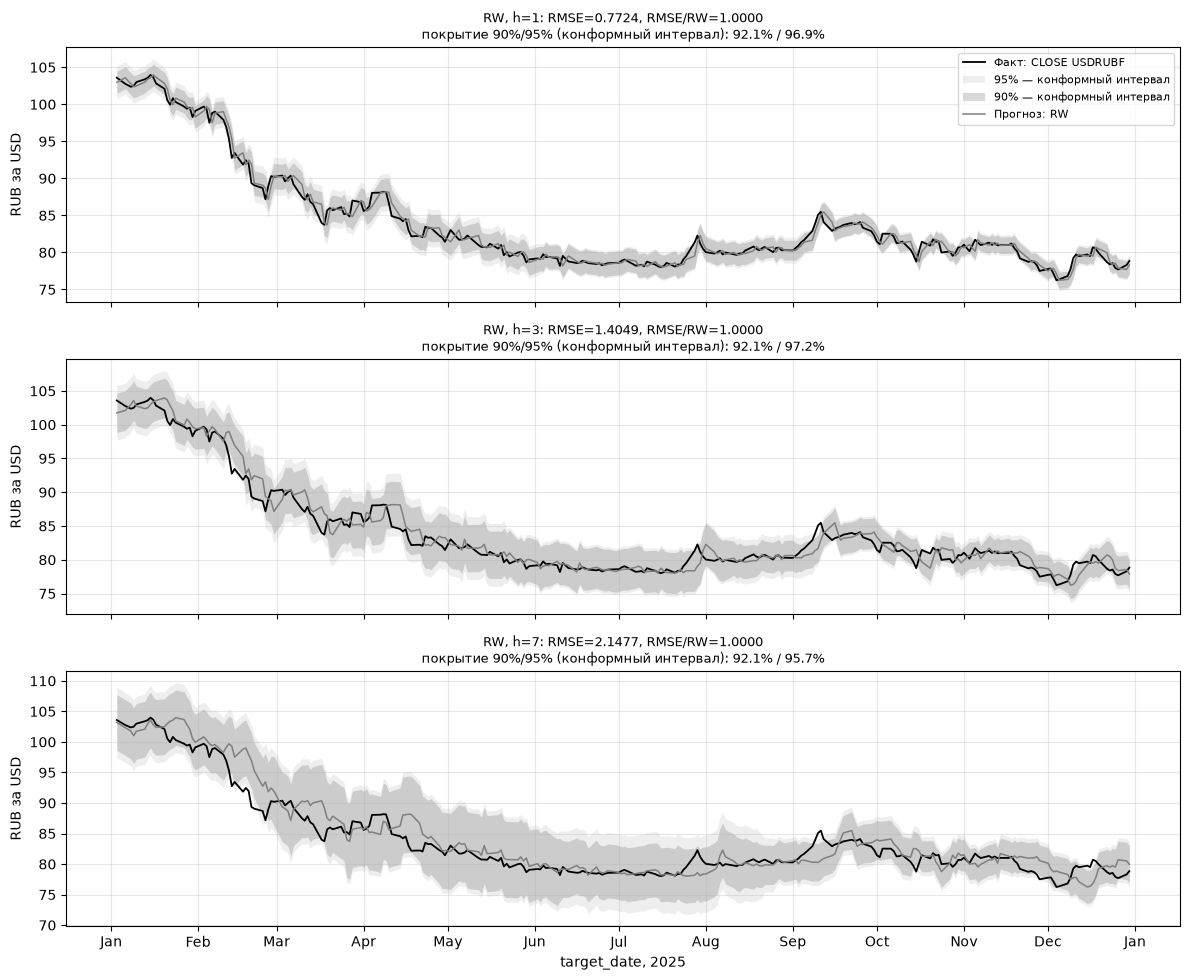

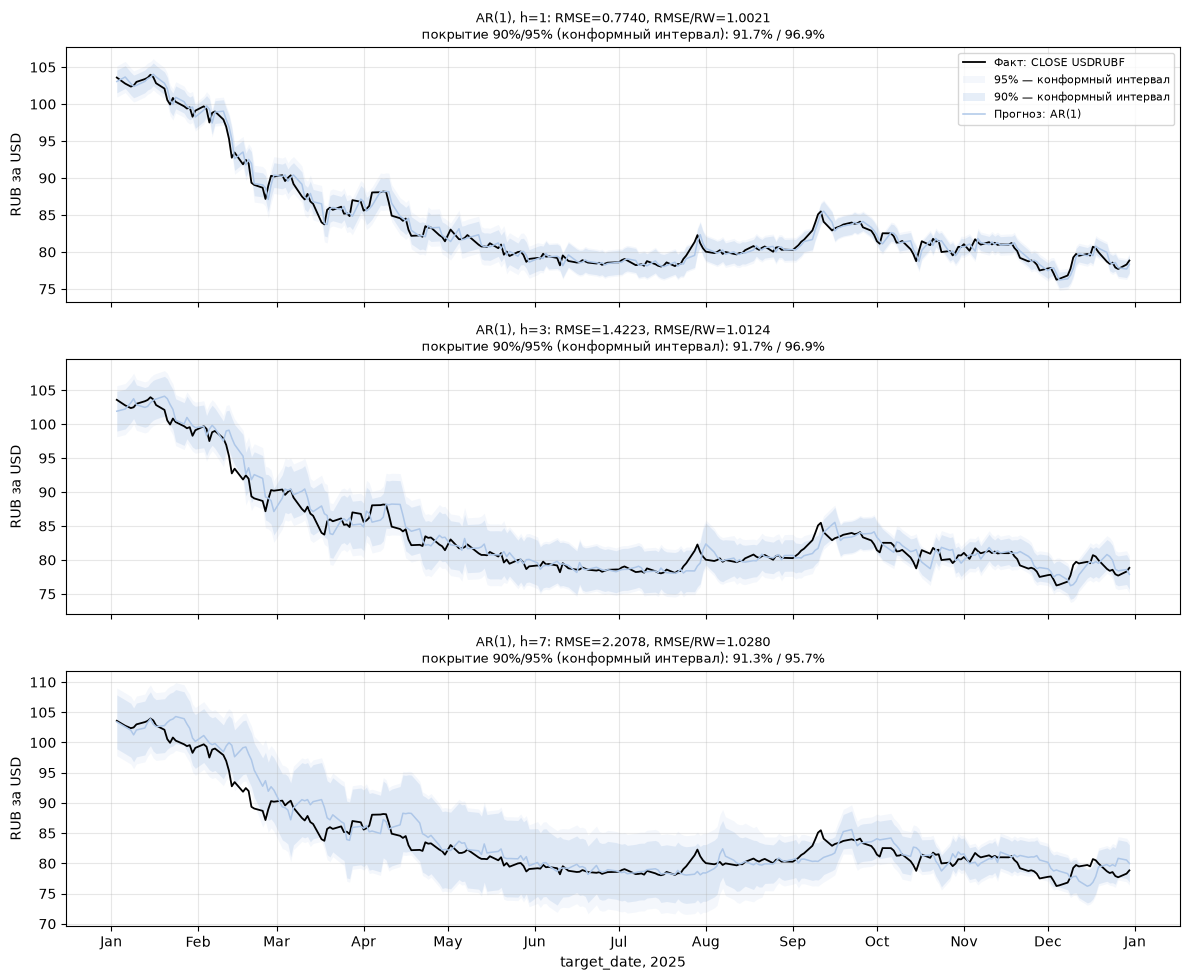

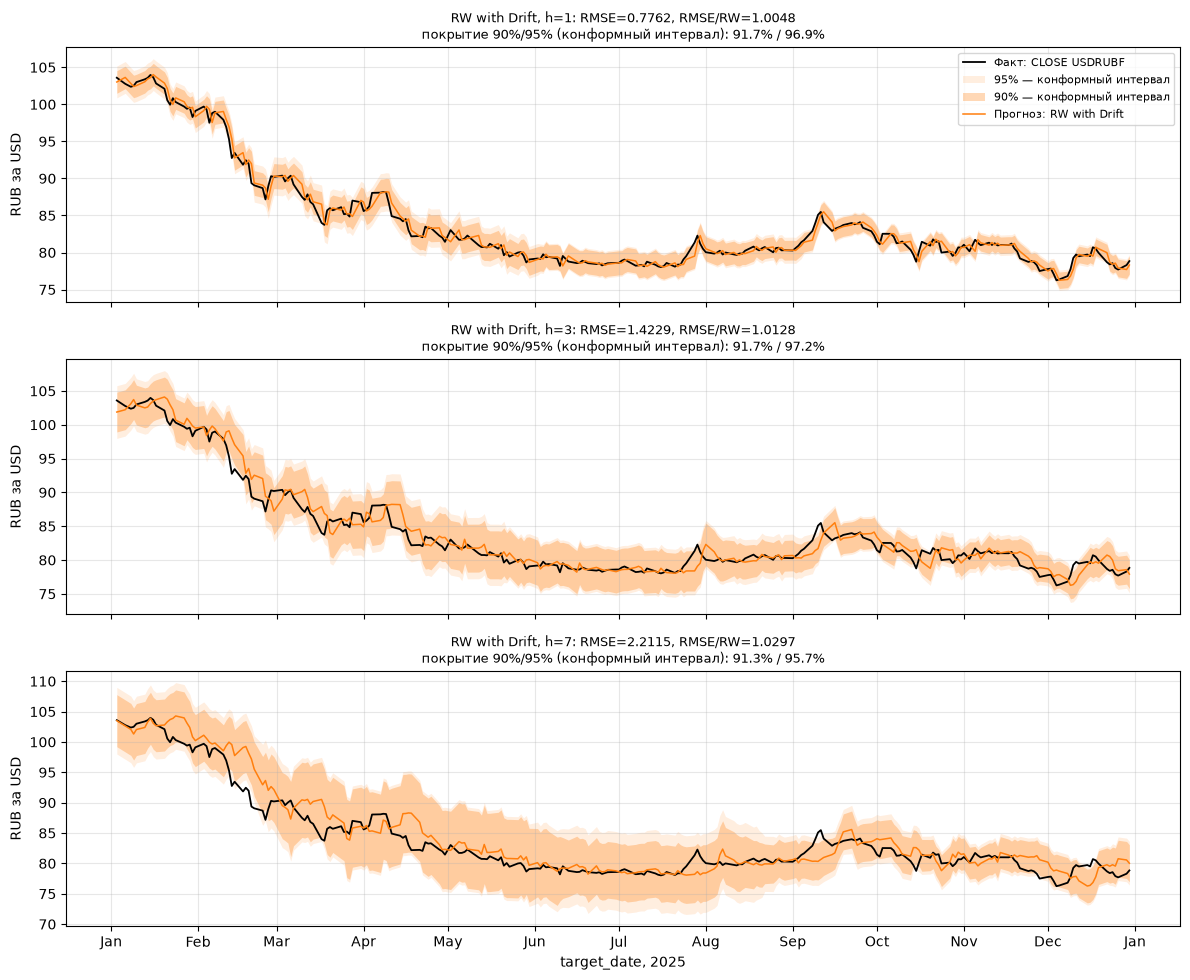

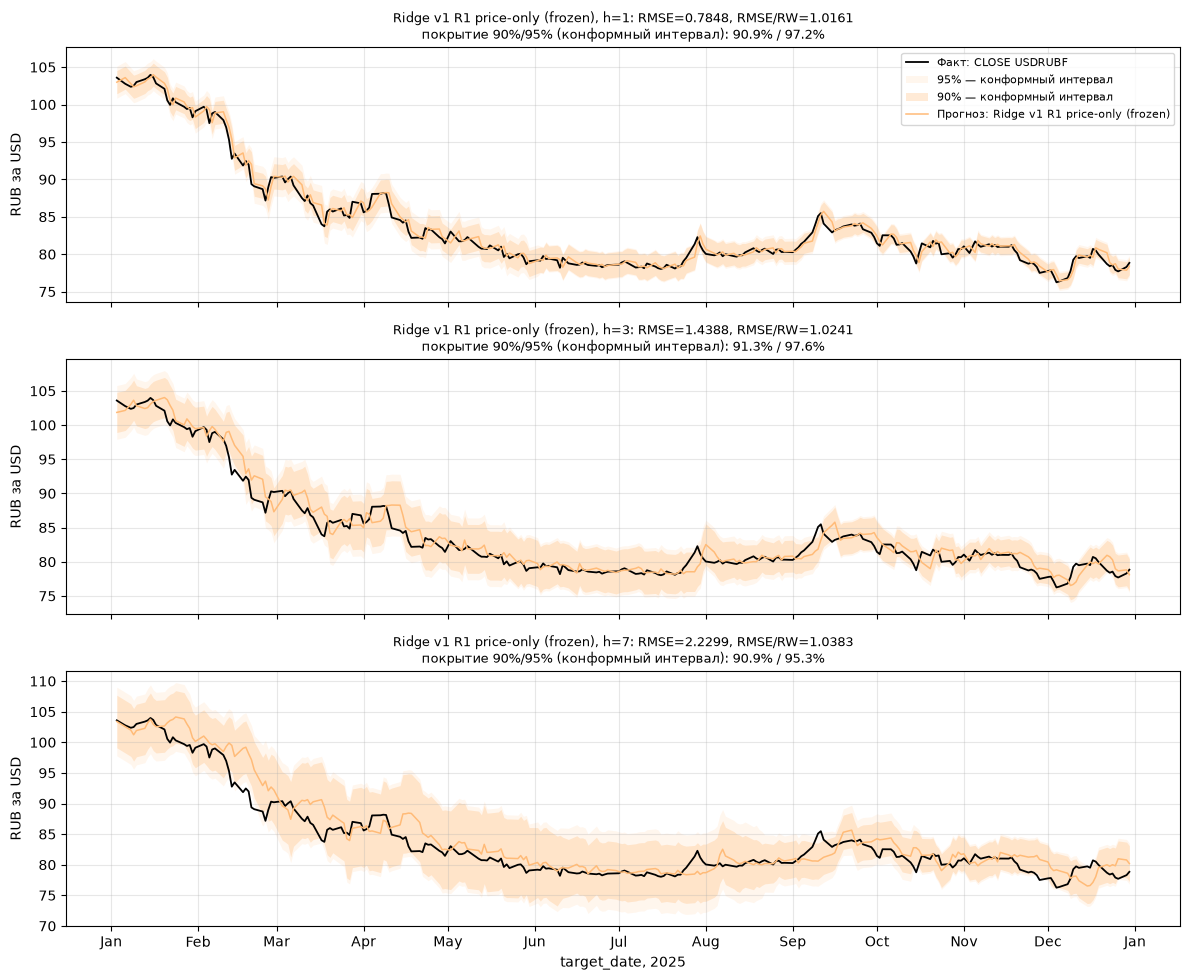

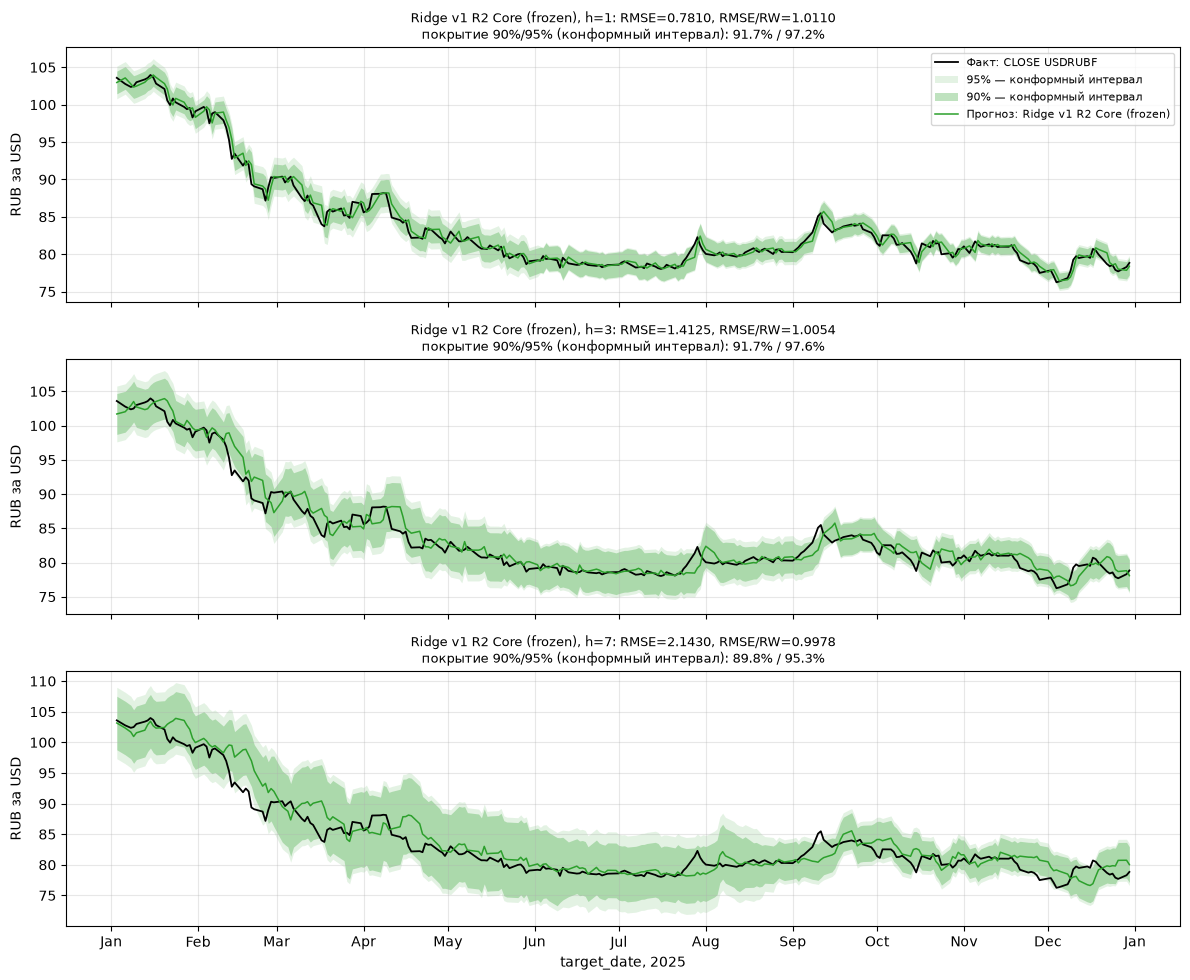

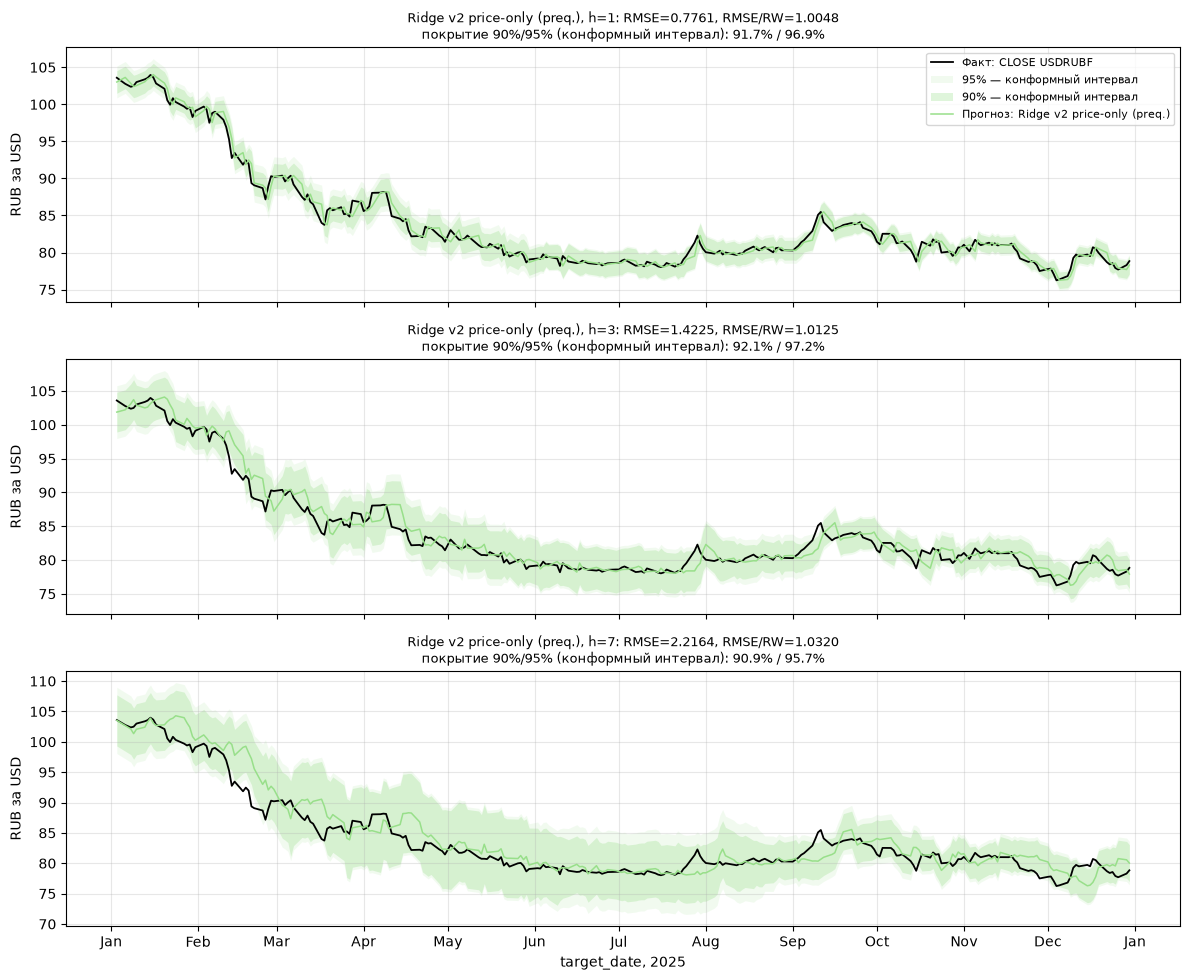

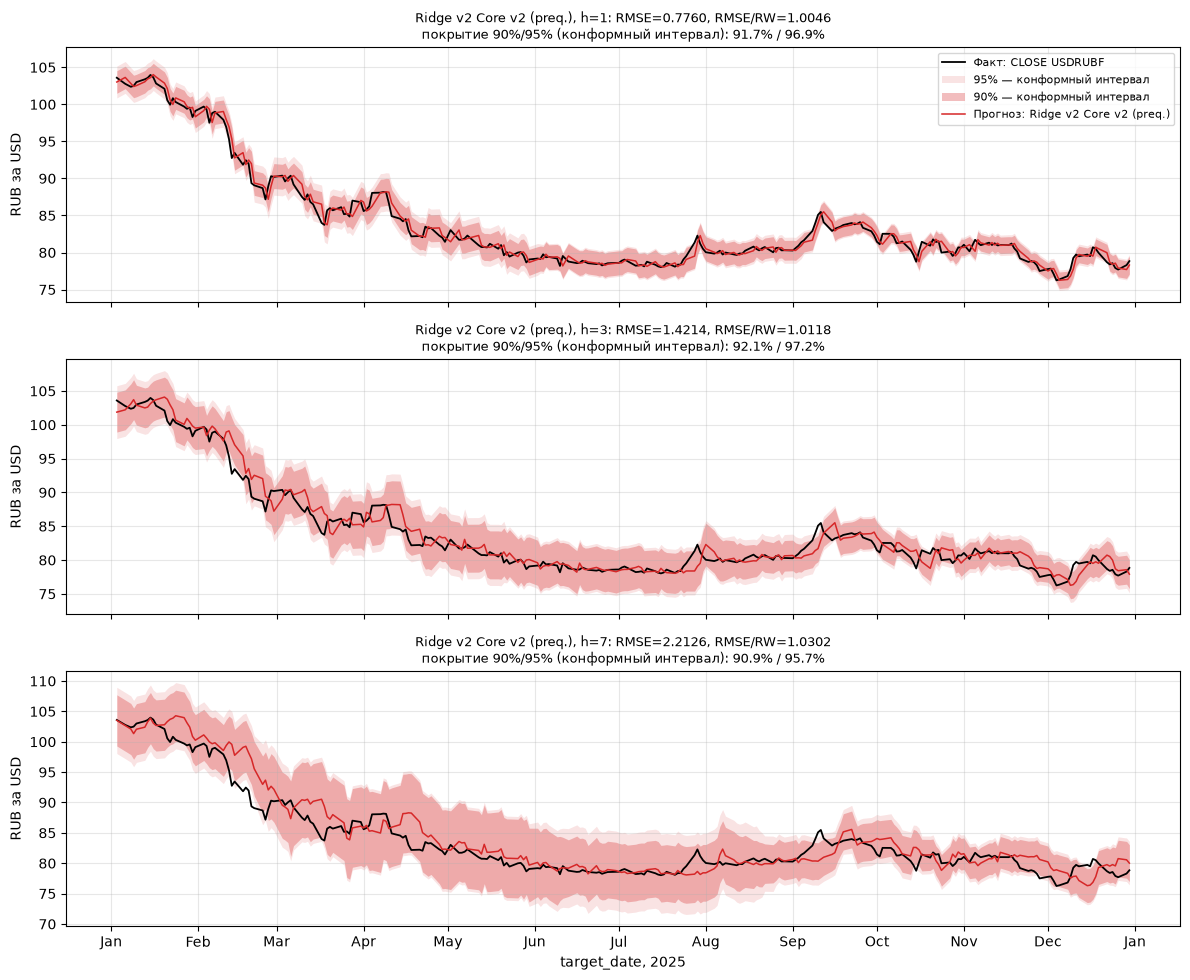

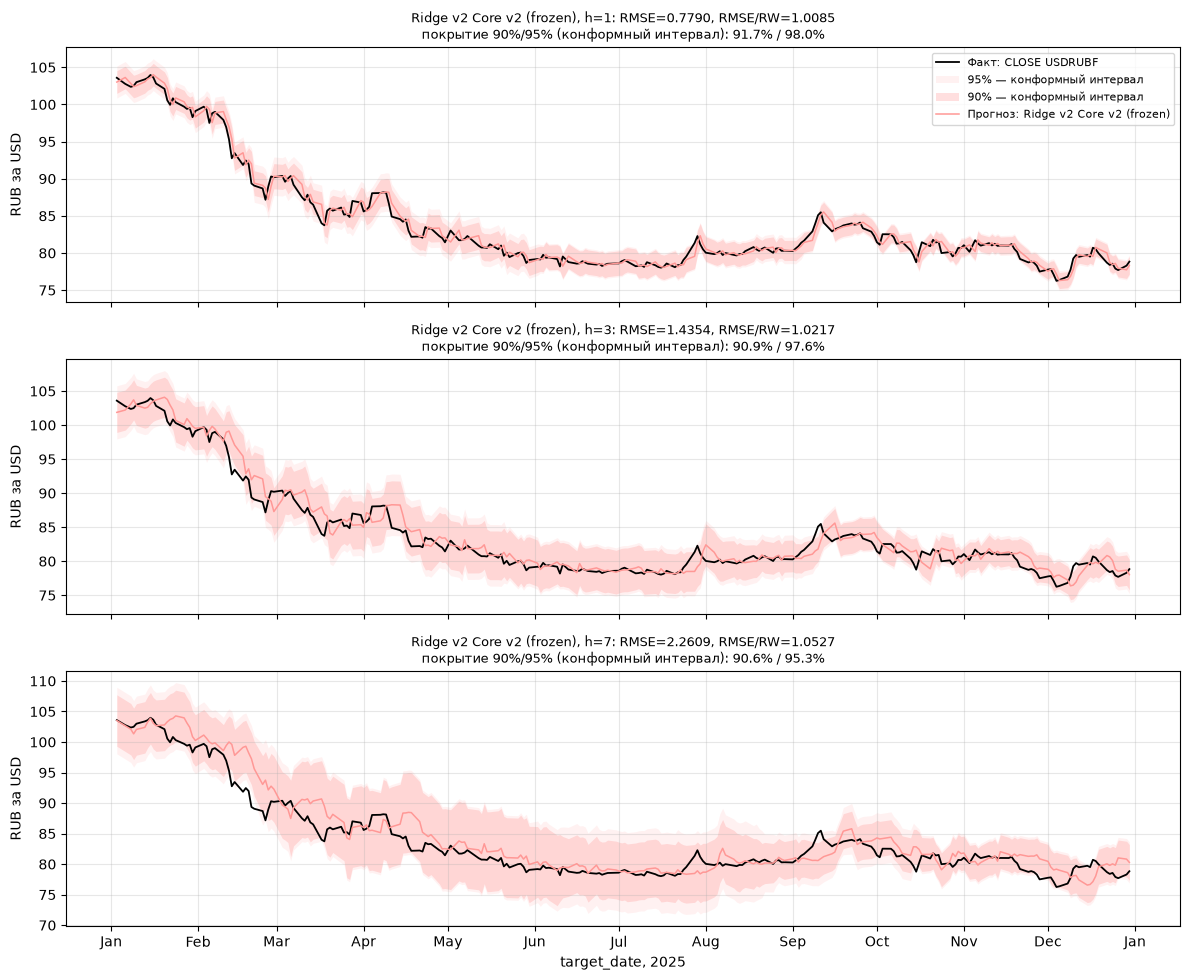

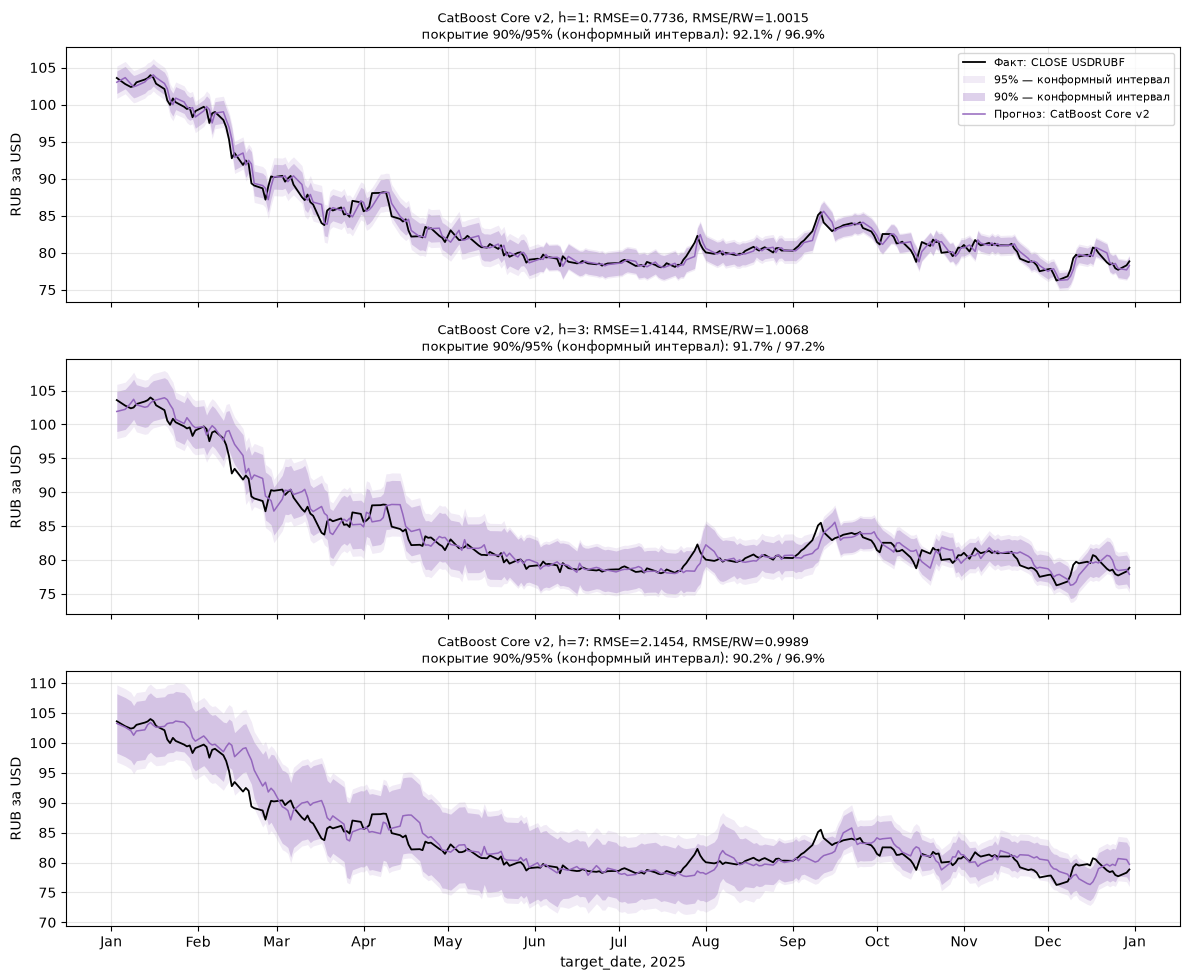

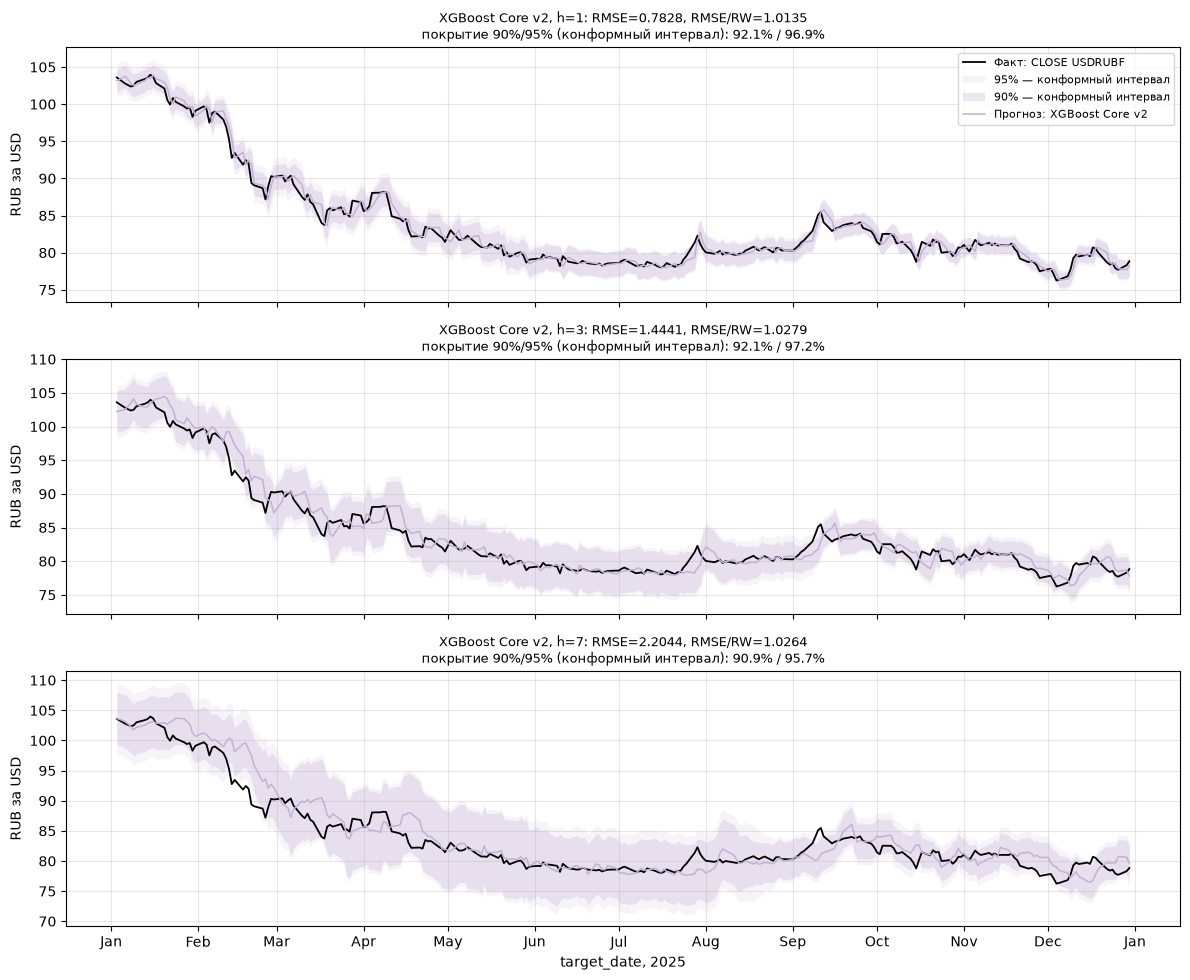

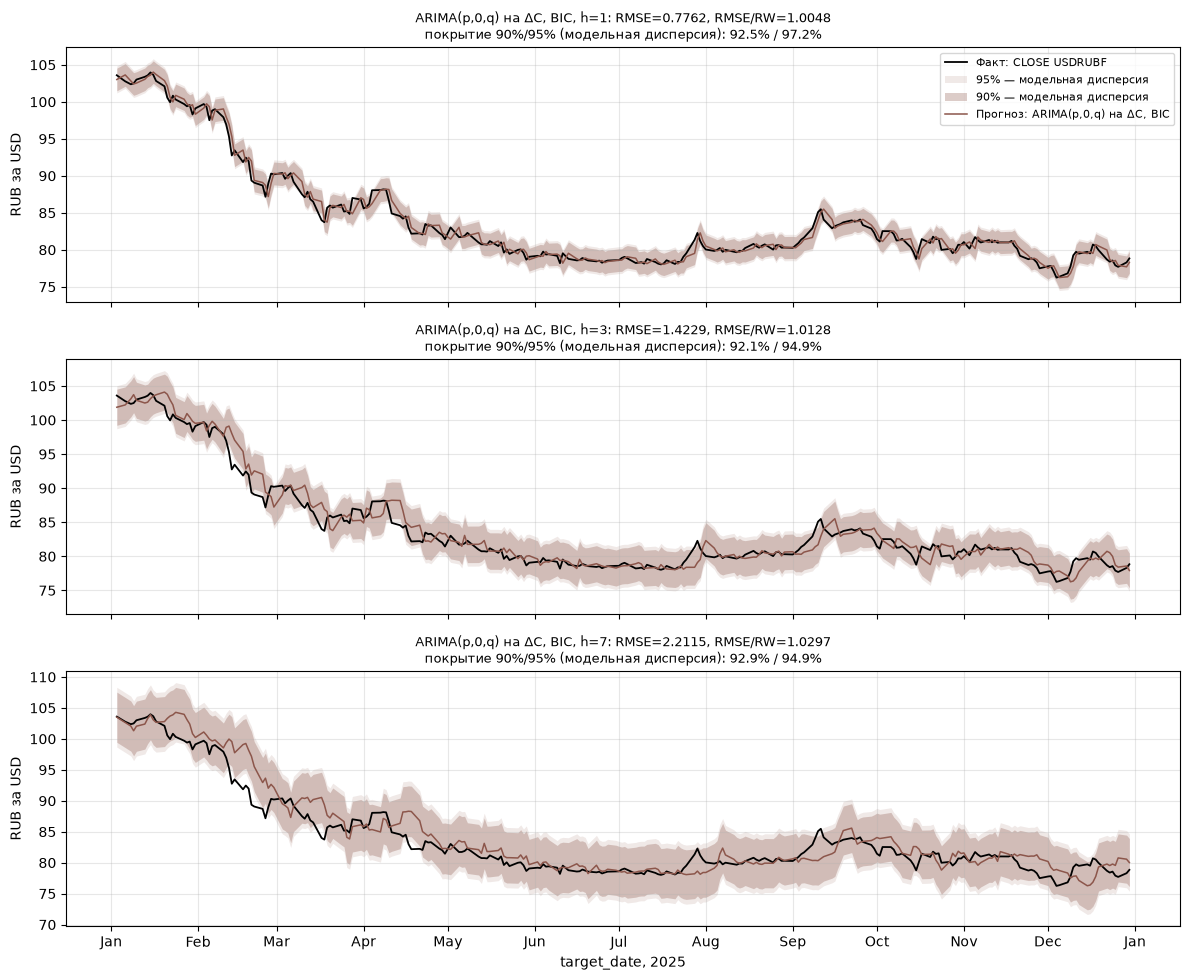

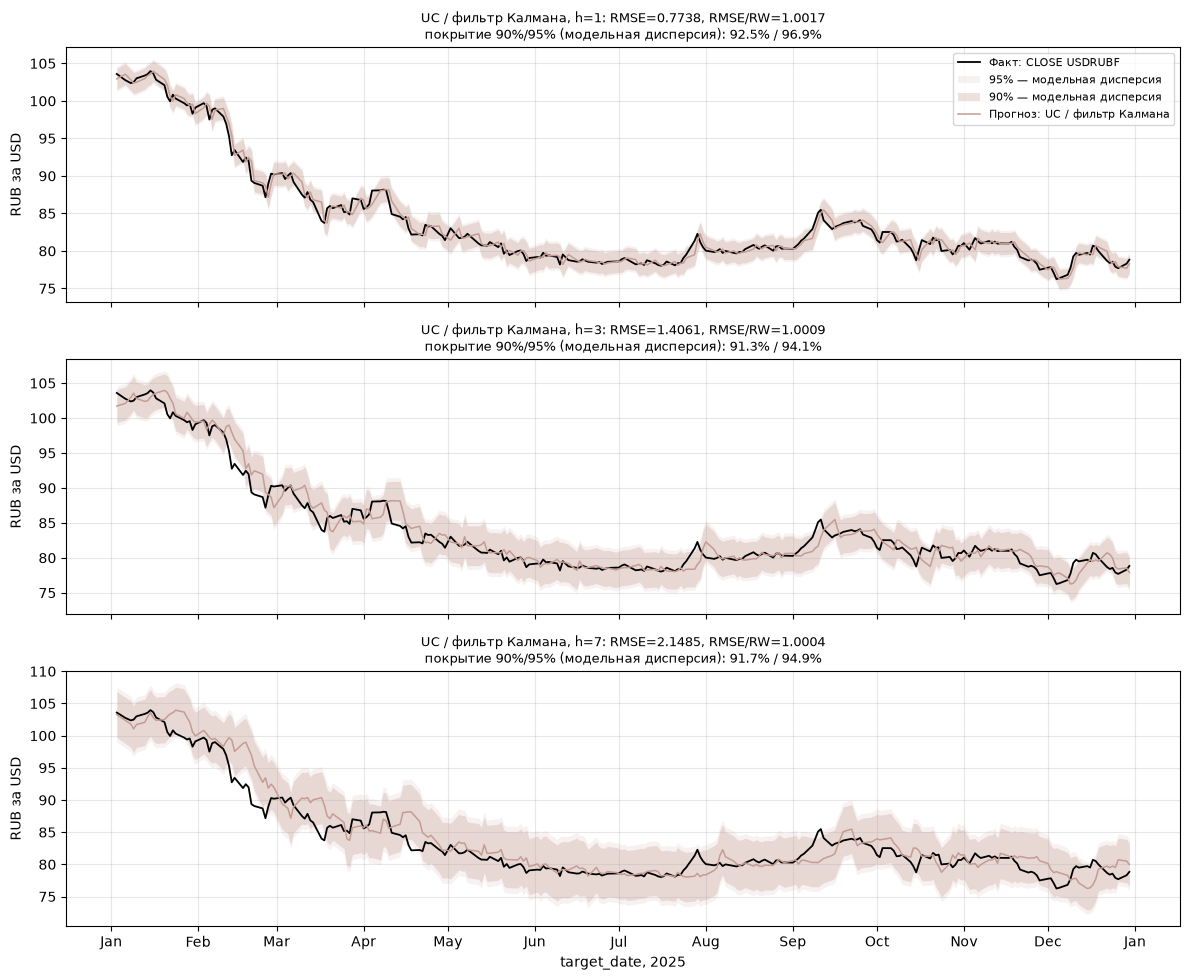

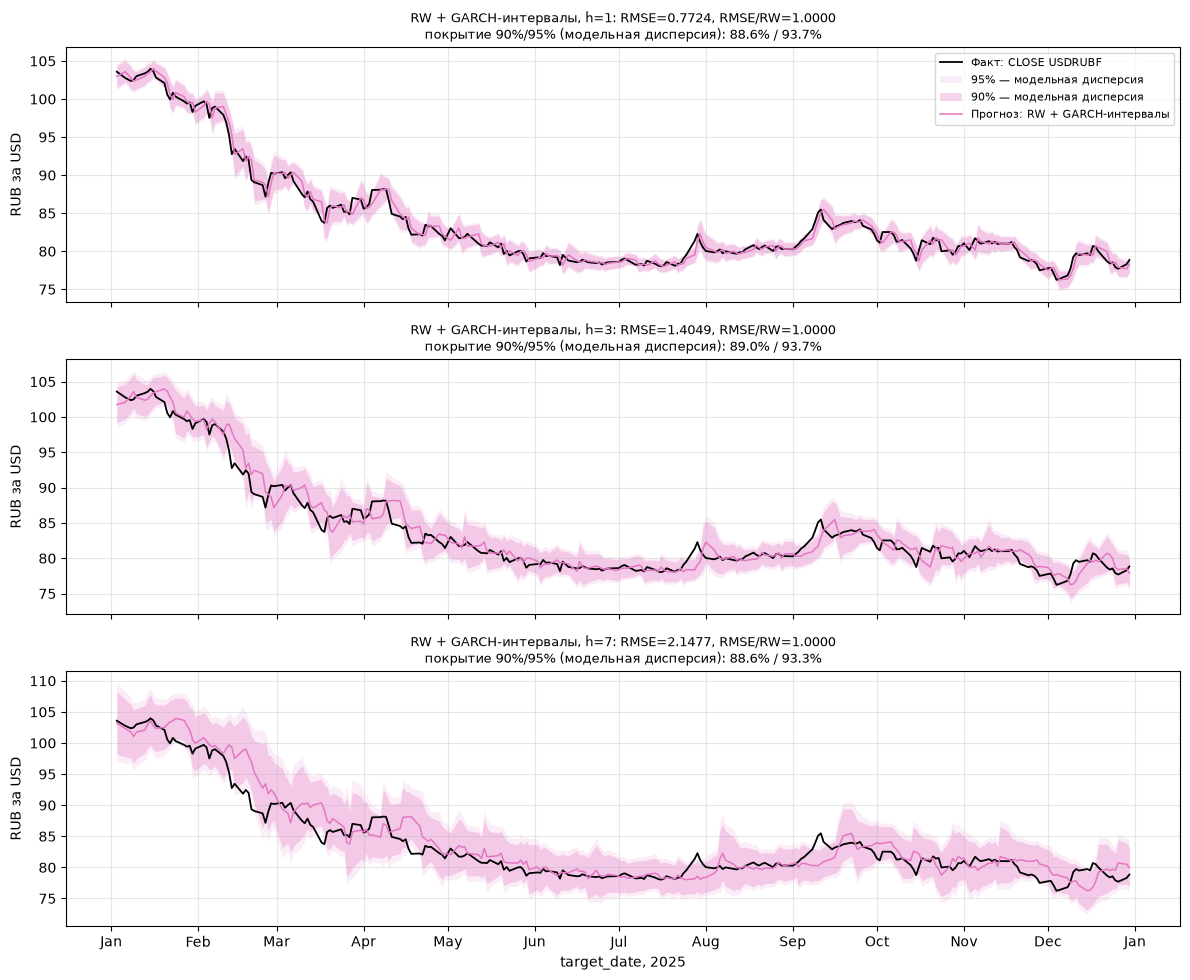

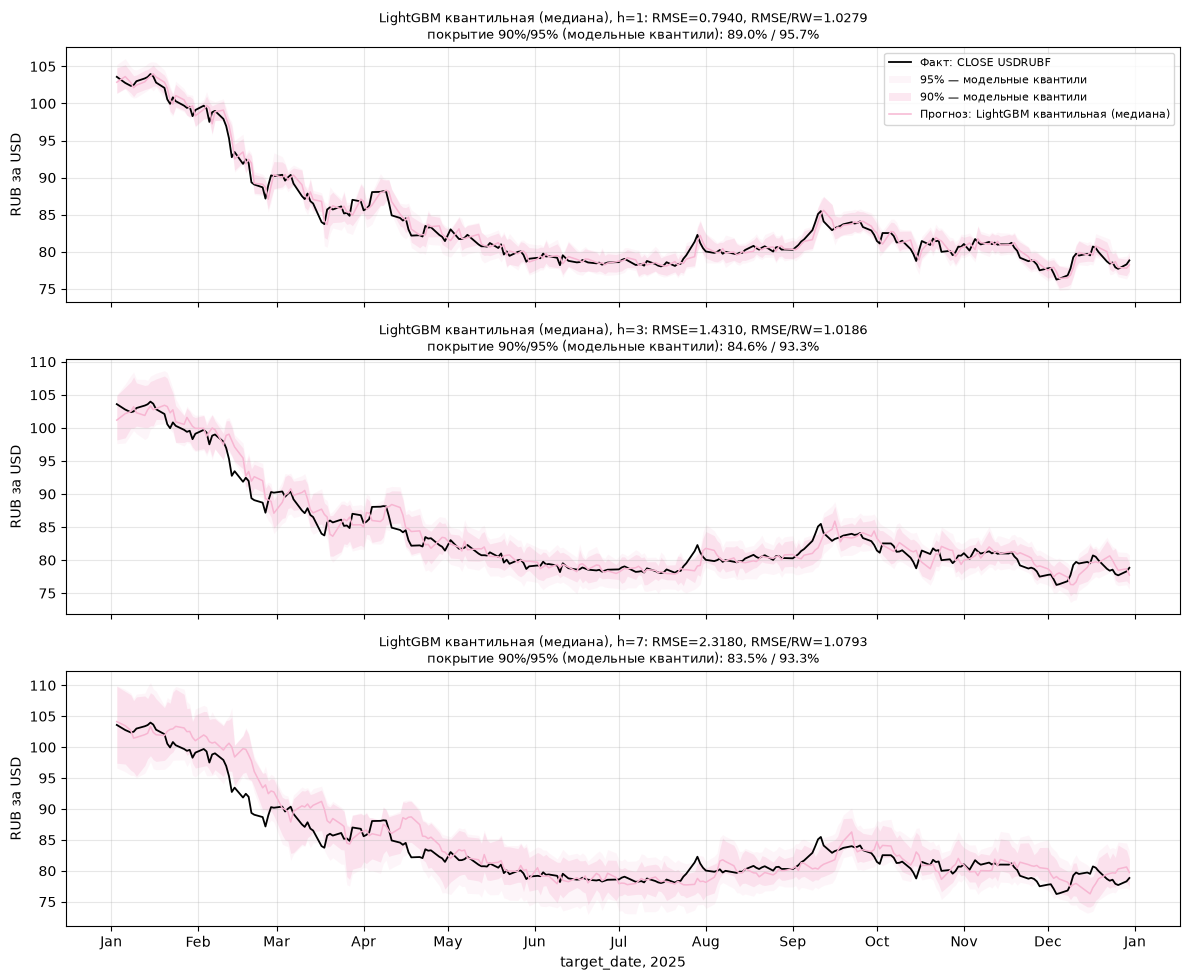

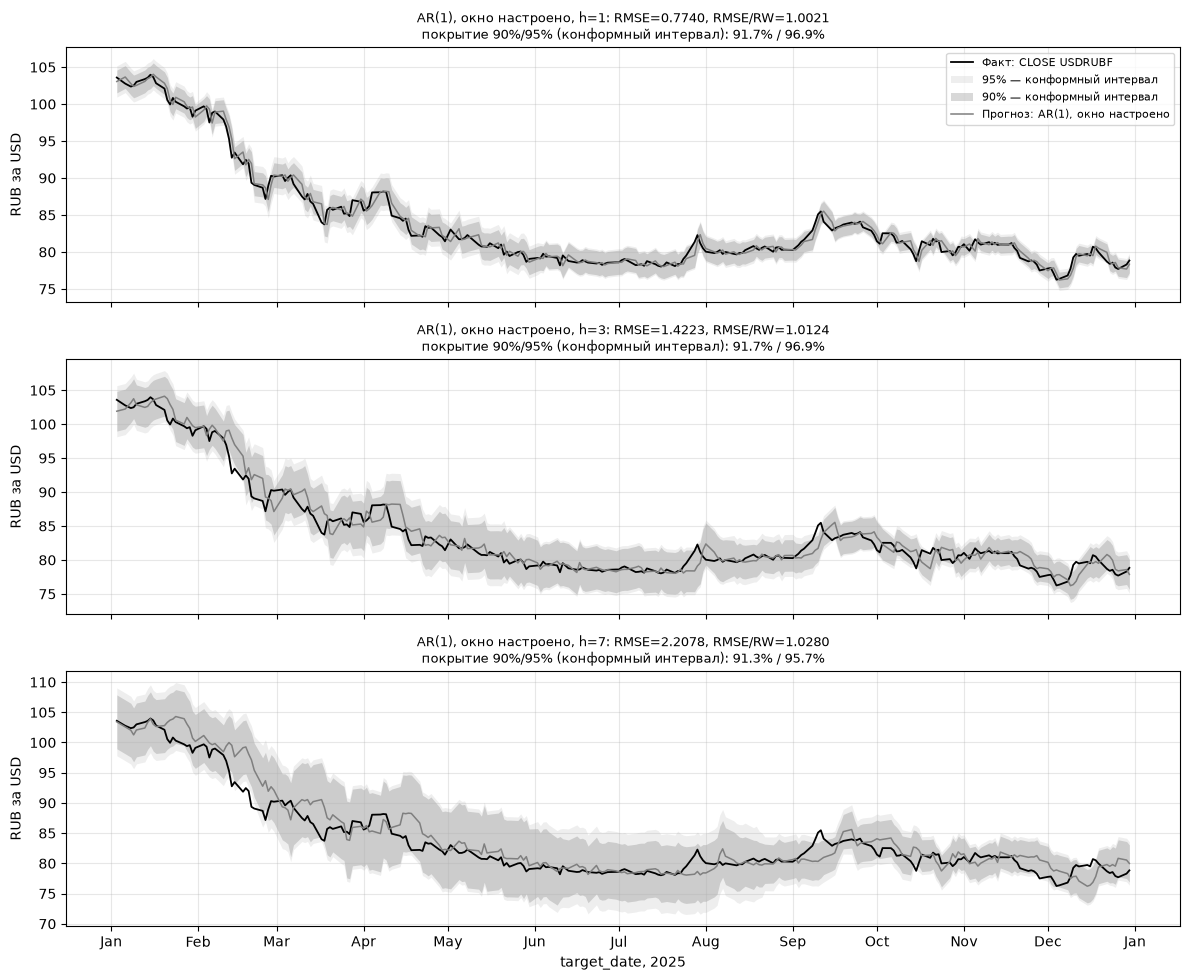

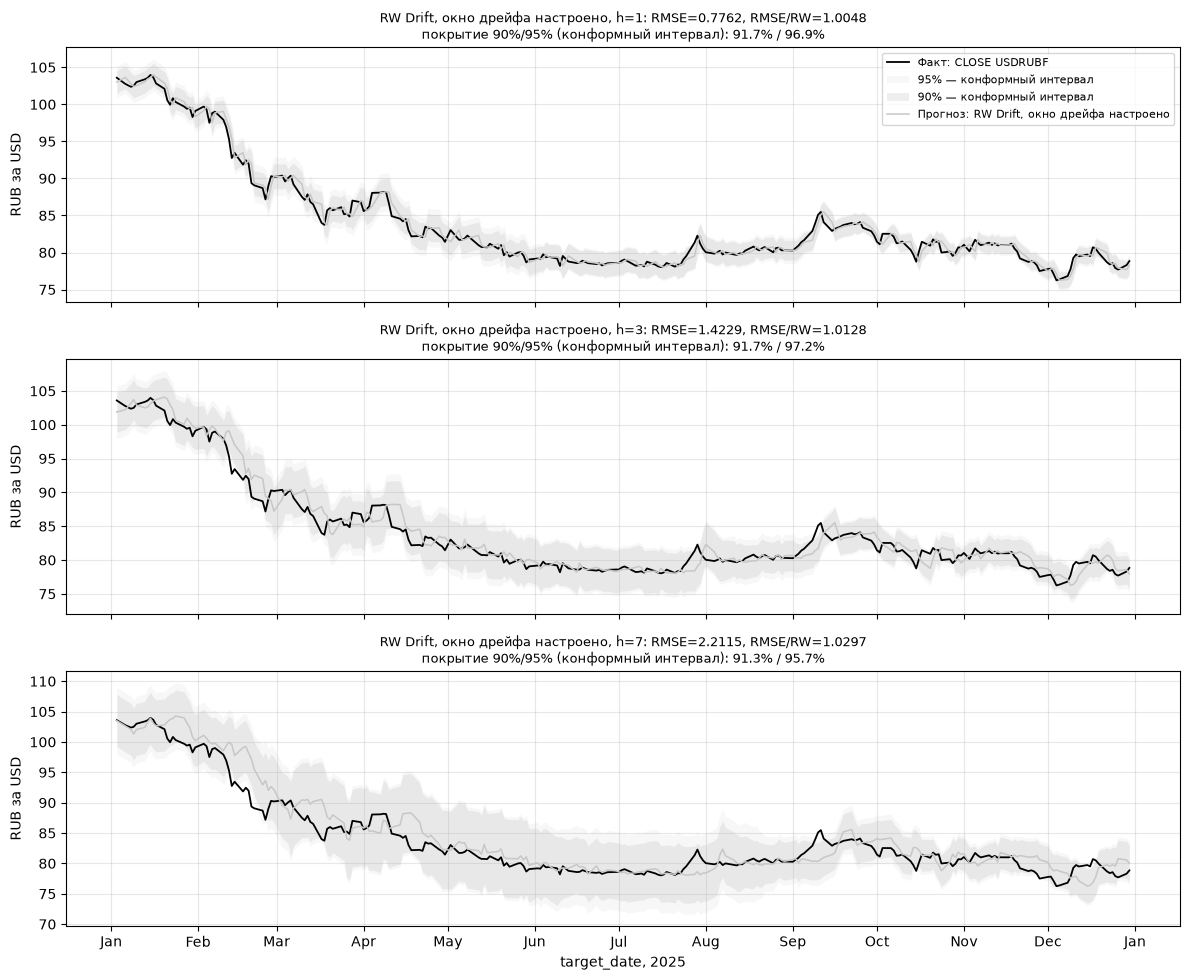

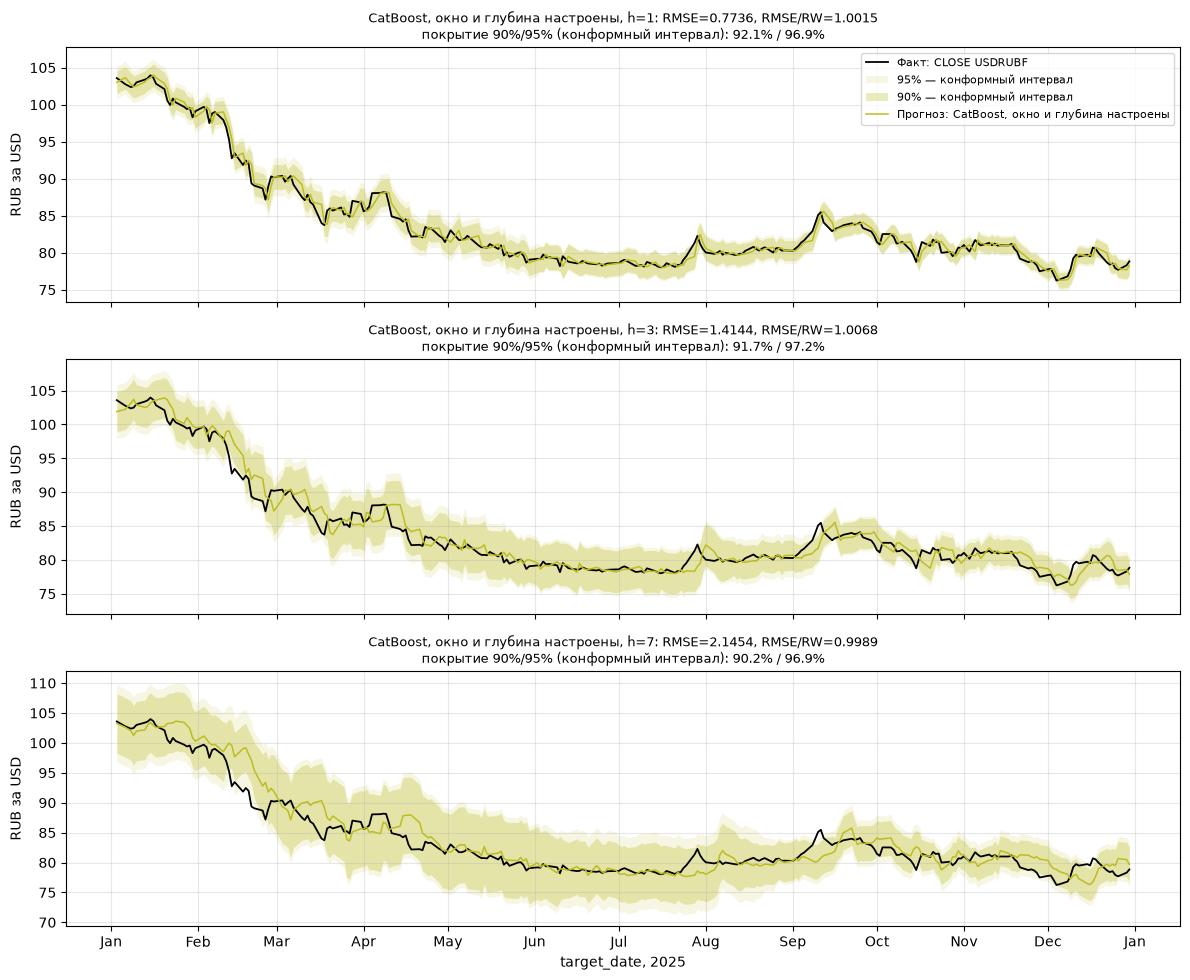

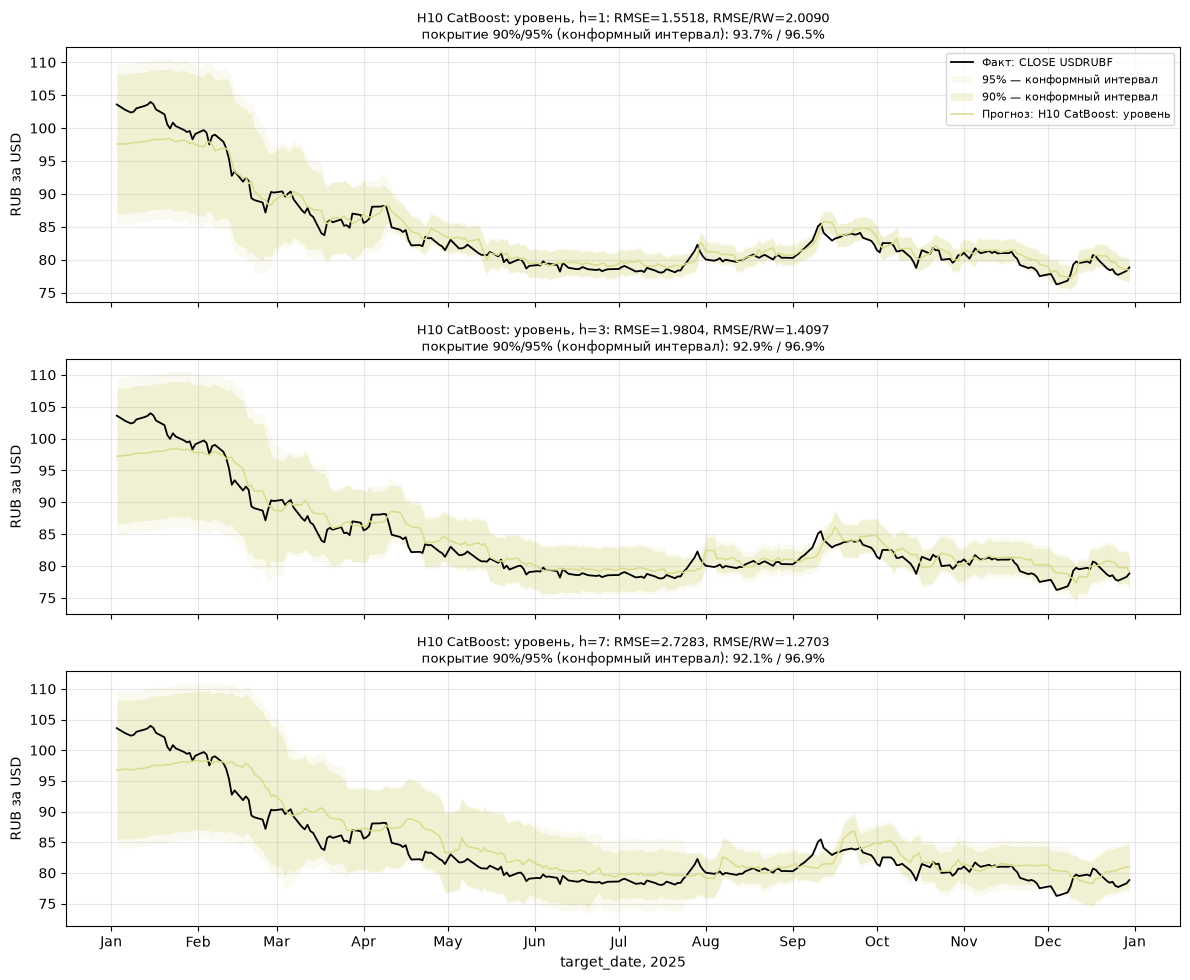

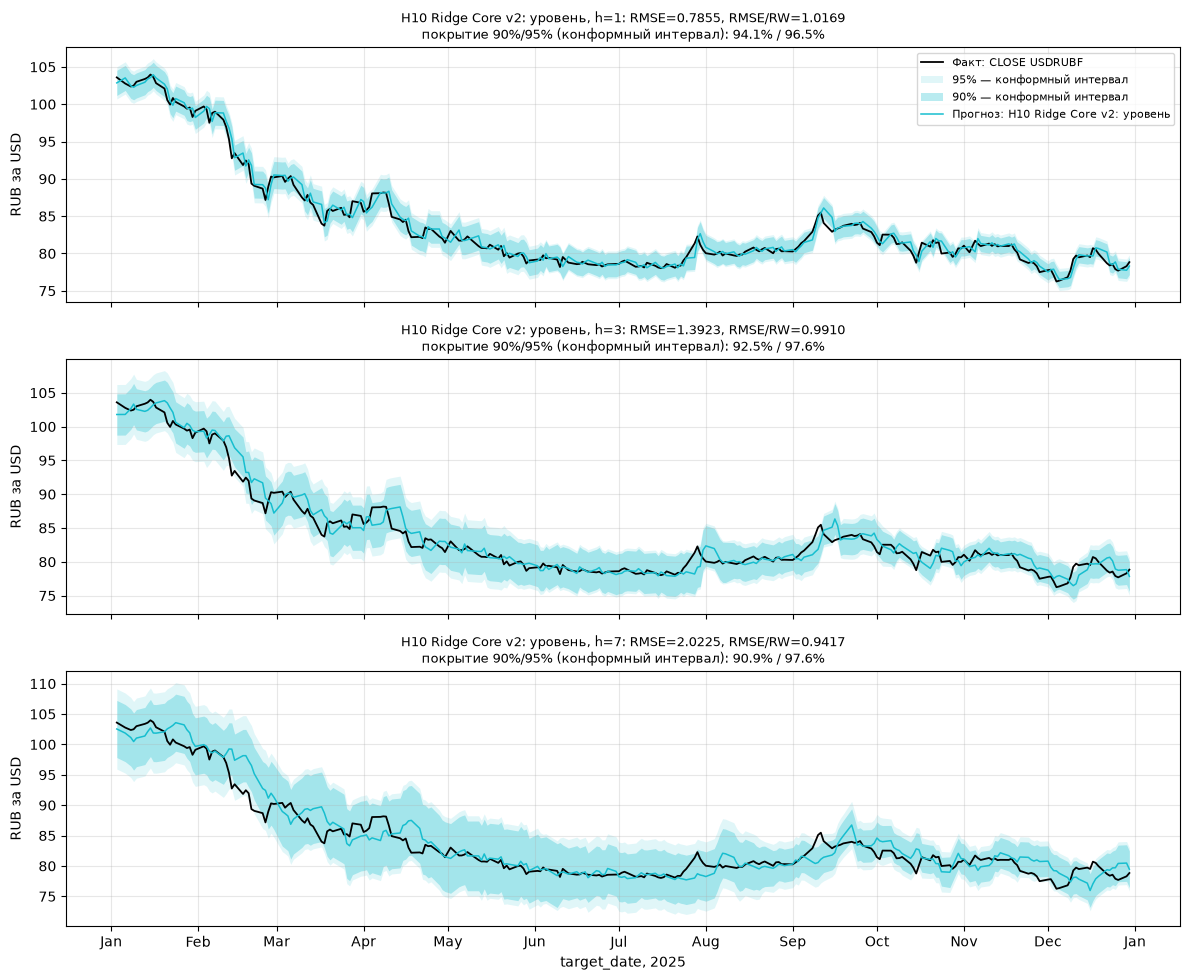

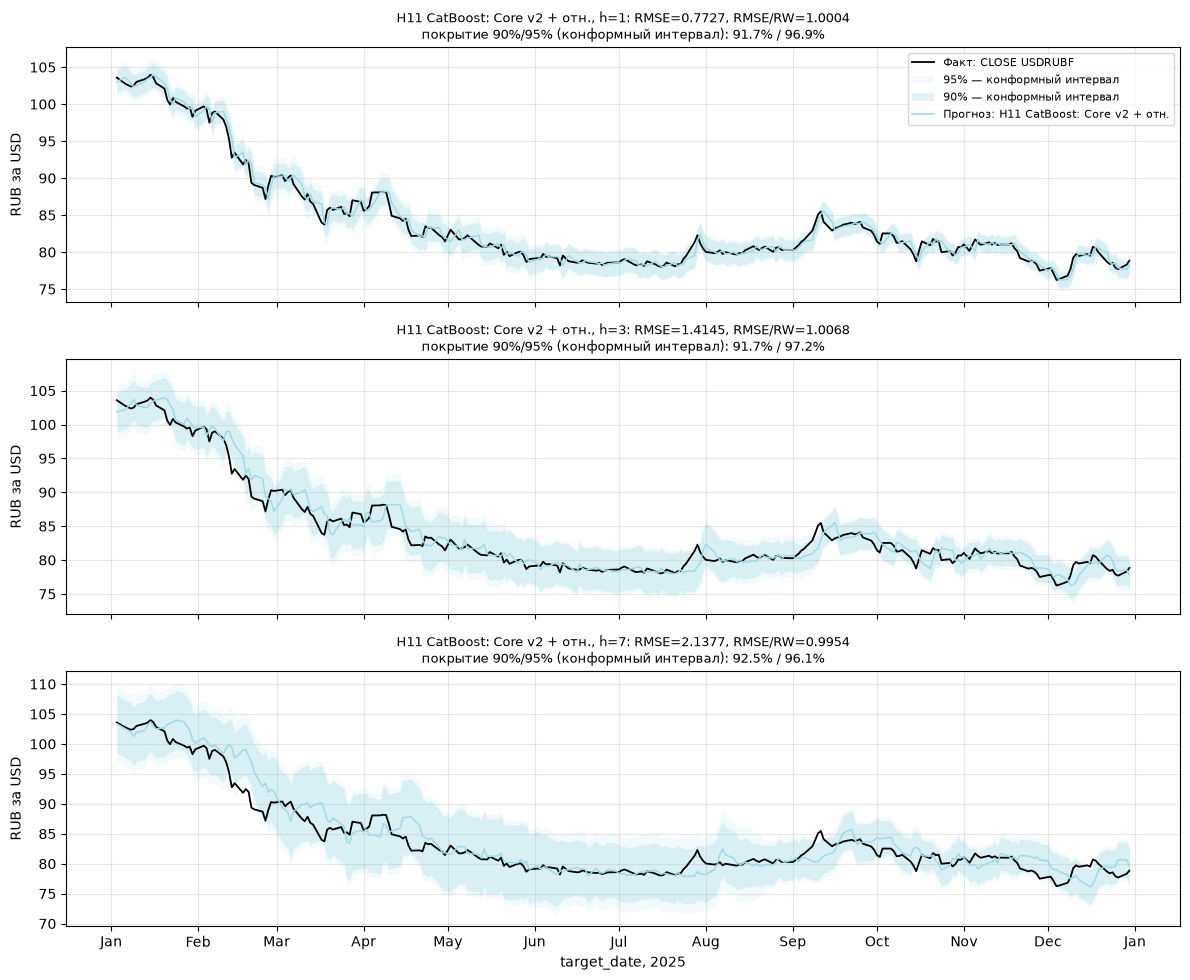

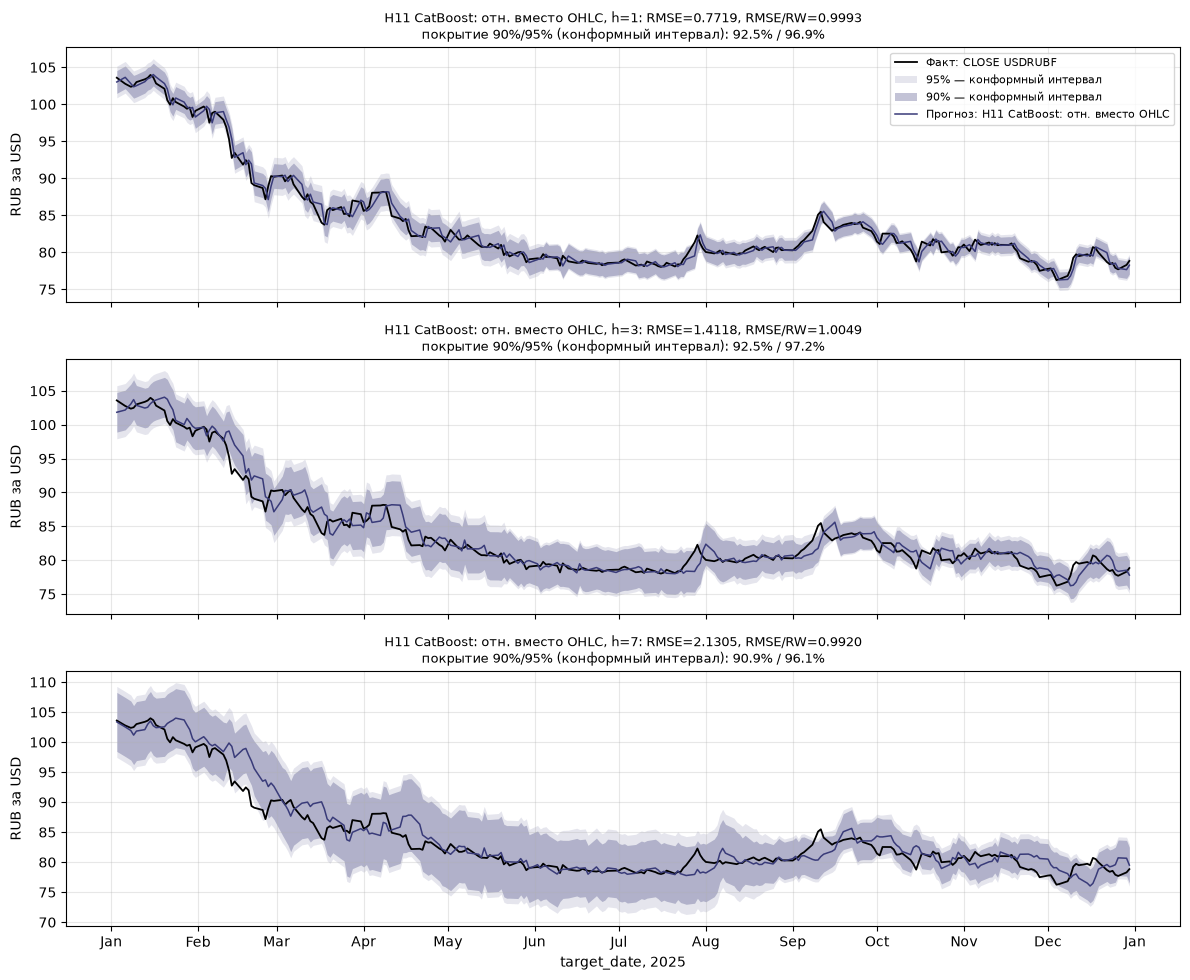

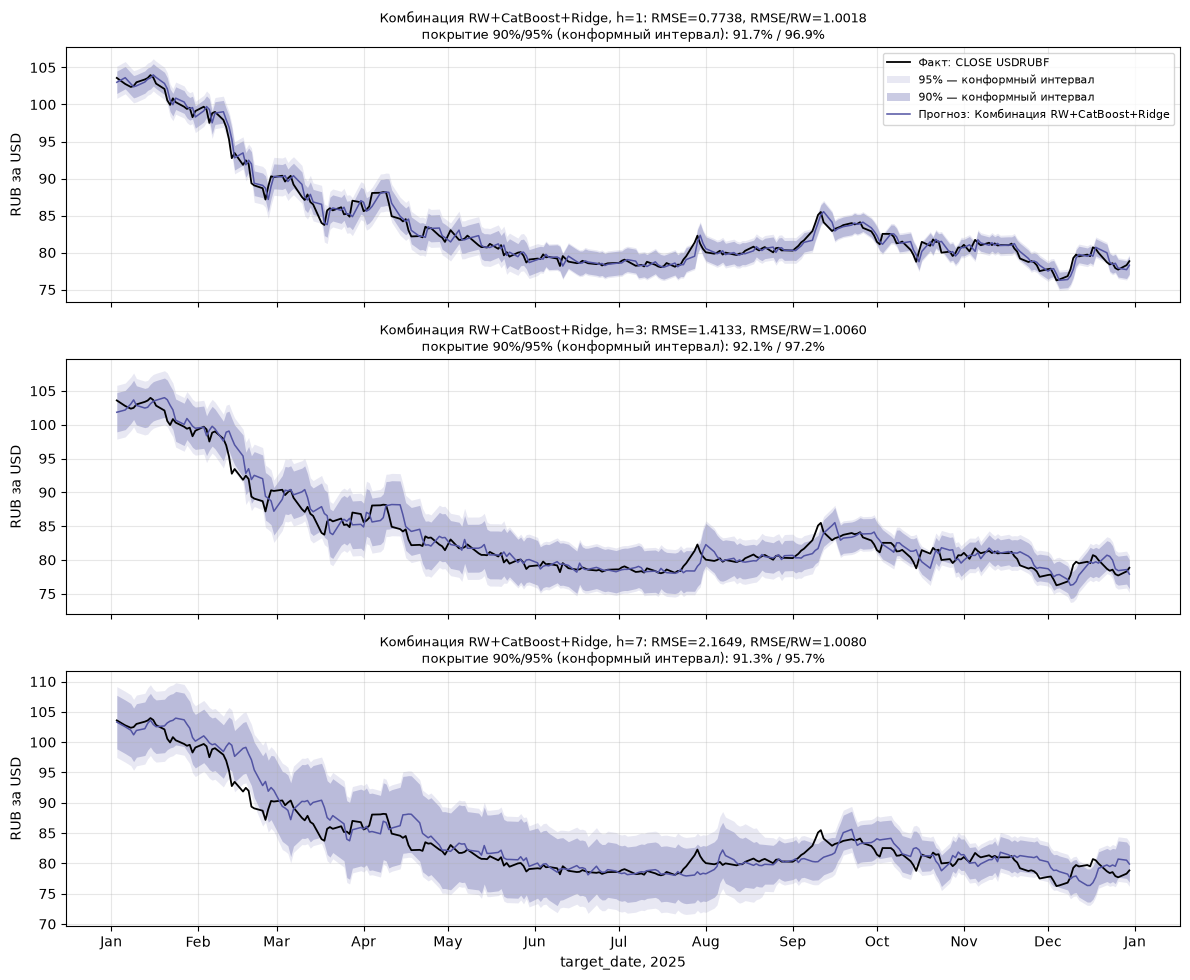

[  748.5 s] figures 5.1


In [19]:
ACTUAL_2025 = close.loc[nm.VAL_START:nm.VAL_END]
COLORS = cp.model_colors(ALL_MODELS)
im = INTERVAL_METRICS.set_index(['model_id', 'interval_source', 'horizon', 'level'])


def plot_data(model_id):
    source = MODEL_INTERVALS.get(model_id, 'conformal')
    base = val(PRED[model_id])[nm.KEYS + ['prediction']]
    bands = INTERVALS.loc[INTERVALS.model_id.eq(model_id) & INTERVALS.interval_source.eq(source),
                          nm.KEYS + ['lower_90', 'upper_90', 'lower_95', 'upper_95']]
    return base.merge(bands, on=nm.KEYS, how='left'), source


def stats(model_id, source):
    out = {}
    for h in nm.HORIZONS:
        r = METRICS.loc[METRICS.model_id.eq(model_id) & METRICS.horizon.eq(h)].iloc[0]
        out[h] = dict(rmse=r.rmse, ratio=r.rmse_ratio_vs_rw, source=cp.SOURCE_LABEL[source],
                      coverage_90=im.loc[(model_id, source, h, 0.90), 'coverage'],
                      coverage_95=im.loc[(model_id, source, h, 0.95), 'coverage'])
    return out


for model_id in ALL_MODELS:
    data, source = plot_data(model_id)
    st = stats(model_id, source)
    for h in nm.HORIZONS:
        fig = cp.model_figure(data, ACTUAL_2025, LABELS[model_id], [h], st, COLORS[model_id], source)
        fig.savefig(FIG / f'model_{model_id}_h{h}.png', dpi=150)
        plt.close(fig)
    fig = cp.model_figure(data, ACTUAL_2025, LABELS[model_id], [1, 3, 7], st, COLORS[model_id], source)
    fig.savefig(FIG / f'model_{model_id}_h1_3_7.png', dpi=150)
    plt.show()
lap('figures 5.1')

## 8. Графики 5.2: все модели на одной фигуре и RMSE/RW

Факт — толстая чёрная линия, модели — тонкие линии (чередуются сплошные и пунктирные), интервалов нет. Нижняя панель увеличивает окно около 3 месяцев (63 сессии) с наибольшим суммарным абсолютным дневным движением фактического курса. Показаны h = 1 и h = 7; остальные h сохранены в `figures/all_models_h<h>.png`. RW + GARCH на этих графиках не рисуется: её точечный прогноз совпадает с RW.

Окно увеличения: 2025-01-21 — 2025-04-17


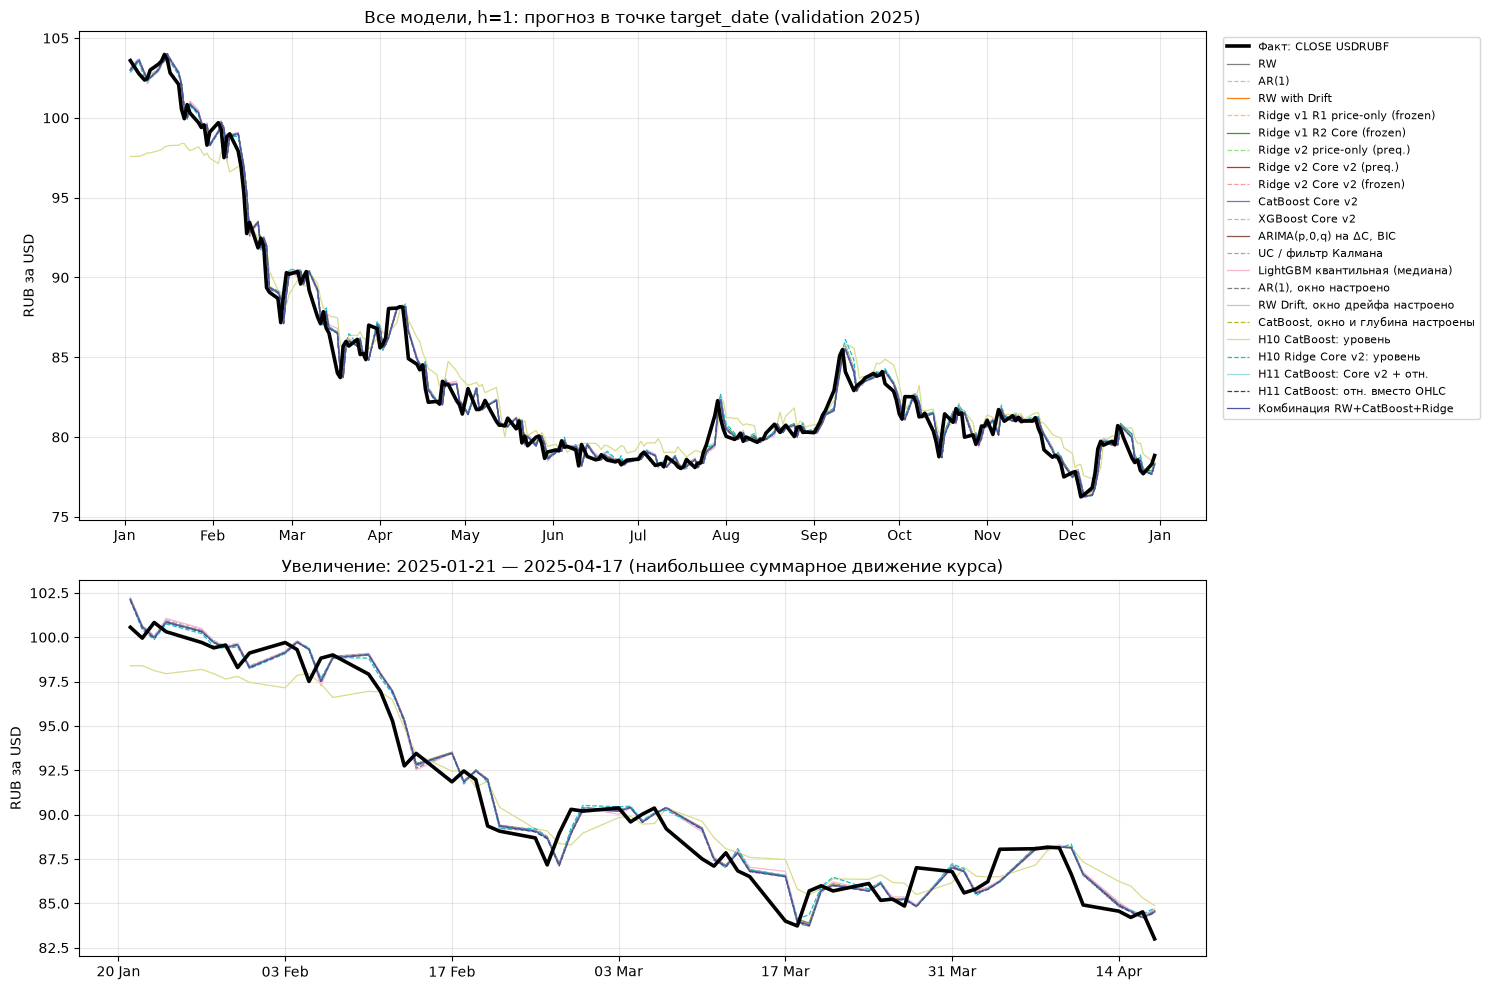

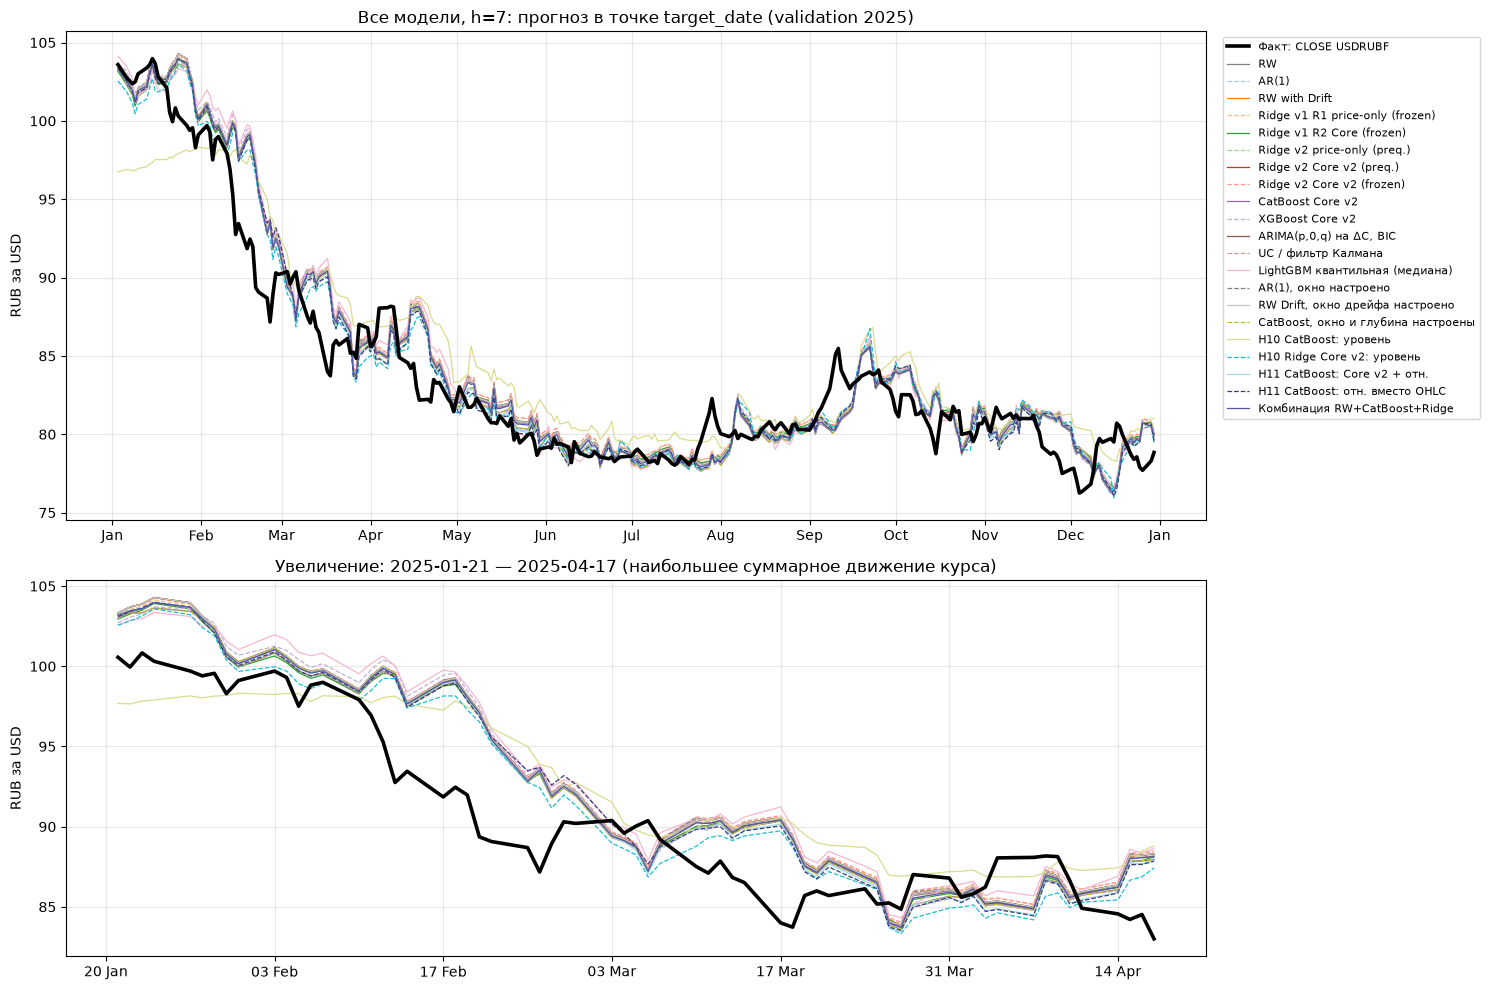

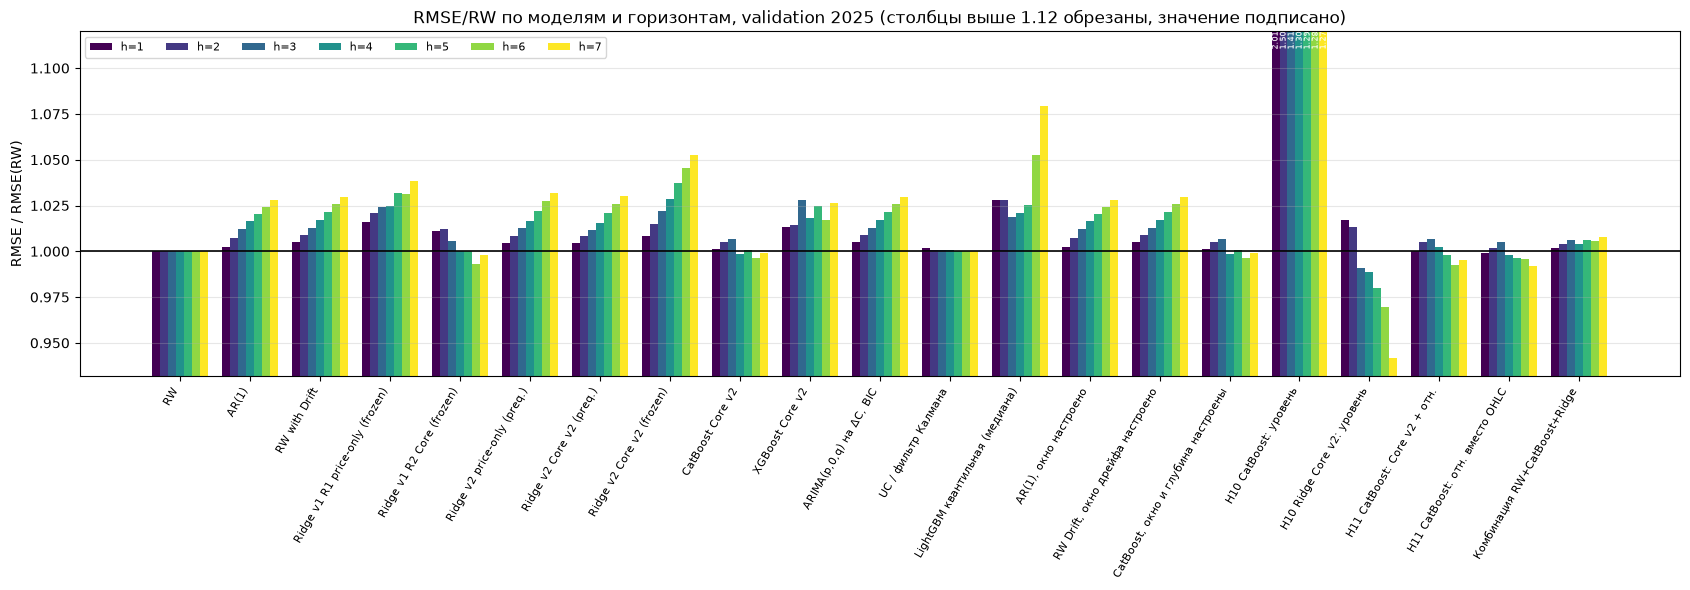

PNG-файлов в figures/: 184
[  751.3 s] figures 5.2


In [20]:
ZOOM = cp.zoom_window(ACTUAL_2025, sessions=63)
LINE_MODELS = [m for m in ALL_MODELS if m != 'RW_GARCH']
print('Окно увеличения:', ZOOM[0].date(), '—', ZOOM[1].date())
for h in nm.HORIZONS:
    fig = cp.all_models_figure(VAL_PRED, ACTUAL_2025, h, LINE_MODELS, LABELS, COLORS, ZOOM)
    fig.savefig(FIG / f'all_models_h{h}.png', dpi=150, bbox_inches='tight')
    if h in (1, 7):
        plt.show()
    else:
        plt.close(fig)
fig = cp.rmse_ratio_bars(METRICS, LINE_MODELS, LABELS)
fig.savefig(FIG / 'rmse_ratio_vs_rw_bars.png', dpi=150, bbox_inches='tight')
plt.show()
print('PNG-файлов в figures/:', len(list(FIG.glob('*.png'))))
lap('figures 5.2')

## 9. Проверки: ни одной даты 2026 года, отсутствие утечек, неизменность защищённых файлов, manifest

In [21]:
checks = {}
checks['panel_max_date_before_2026'] = idx.max() < nm.FINAL_TEST_START
checks['ridge_v1_v2_frames_before_2026'] = frame_v1.index.max() < nm.FINAL_TEST_START and frame_v2.index.max() < nm.FINAL_TEST_START
checks['price_loader_before_2026'] = base_data.index.max() < nm.FINAL_TEST_START
all_pred = pd.concat(PRED.values(), ignore_index=True)
checks['all_origins_before_2026'] = all_pred.origin_date.max() < nm.FINAL_TEST_START
checks['all_targets_before_2026'] = all_pred.target_date.max() < nm.FINAL_TEST_START
checks['training_label_end_before_2026'] = all_pred.train_label_end.dropna().max() < nm.FINAL_TEST_START
checks['training_label_end_not_after_origin'] = bool((all_pred.dropna(subset=['train_label_end']).train_label_end
                                                      <= all_pred.dropna(subset=['train_label_end']).origin_date).all())
checks['tuning_targets_before_validation'] = inner_keys.target_date.max() < nm.VAL_START
checks['metrics_targets_in_2025'] = SCORED.target_date.between(nm.VAL_START, nm.VAL_END).all()
checks['interval_targets_in_2025'] = INTERVALS.target_date.between(nm.VAL_START, nm.VAL_END).all()
checks['conformal_uses_matured_errors_only'] = bool((conf_all.calibration_end_date <= conf_all.origin_date).all())
checks['plotted_actuals_in_2025'] = ACTUAL_2025.index.min() >= nm.VAL_START and ACTUAL_2025.index.max() <= nm.VAL_END
checks['common_keys_254_per_h'] = bool(METRICS.n.eq(254).all())
PROTECTED_AFTER = protected_hashes()
checks['protected_files_unchanged'] = PROTECTED_AFTER == PROTECTED_BEFORE
print(json.dumps({k: bool(v) for k, v in checks.items()}, indent=1))
print('Последняя дата в данных:', idx.max().date(), '| последний target:', all_pred.target_date.max().date(),
      '| последний train label:', all_pred.train_label_end.dropna().max().date())
assert all(checks.values()), 'a constraint check failed'

{
 "panel_max_date_before_2026": true,
 "ridge_v1_v2_frames_before_2026": true,
 "price_loader_before_2026": true,
 "all_origins_before_2026": true,
 "all_targets_before_2026": true,
 "training_label_end_before_2026": true,
 "training_label_end_not_after_origin": true,
 "tuning_targets_before_validation": true,
 "metrics_targets_in_2025": true,
 "interval_targets_in_2025": true,
 "conformal_uses_matured_errors_only": true,
 "plotted_actuals_in_2025": true,
 "common_keys_254_per_h": true,
 "protected_files_unchanged": true
}
Последняя дата в данных: 2025-12-30 | последний target: 2025-12-30 | последний train label: 2025-12-29


In [22]:
inputs = ['data/processed/model_dataset_usdrubf_all_features_v2.csv', 'data/processed/features_daily_v1.csv',
          'data/processed/features_daily_v1_metadata.csv', 'data/processed/USDRUBF_baseline_2026-11-18.csv',
          'data/processed/usdrubf_trading_days.csv', 'configs/benchmark_config.yaml', 'configs/ridge_experiments.json',
          'configs/ridge_experiments_v2.json', 'configs/rw_drift_experiment.json', 'configs/catboost_experiment.json',
          'configs/catboost_core_v2_proposal.json', 'configs/xgboost_core_v2.json', 'configs/feature_scenarios_v1.json']
code_files = ['benchmarks/new_models.py', 'benchmarks/comparison_plots.py', 'notebooks/model_comparison_2025.ipynb']
manifest = dict(
    experiment='notebook_comparison_v1', git=nm.git_info(), packages=nm.package_versions(), seed=nm.SEED,
    n_jobs=N_JOBS, input_sha256={p: nm.sha256(ROOT / p) for p in inputs},
    implementation_sha256_lf={p: __import__('hashlib').sha256((ROOT / p).read_bytes().replace(b'\r\n', b'\n')).hexdigest()
                              for p in code_files[:2]},
    note_notebook_hash='the notebook hash is not stored: it changes when outputs are written',
    data_cutoff=str(idx.max().date()), validation_targets=design['validation_targets'],
    models=ALL_MODELS, selections=selected_json, checks={k: bool(v) for k, v in checks.items()},
    reproduction_all_within_1e_6=bool(REPRO.pass_csv.all()), reproduction_report_tables_match=bool(REPRO.pass_report.all()),
    boosting_selections_match_saved={m: REPLAY[m]['selections_match_saved'] for m in REPLAY},
    timings_seconds=TIMINGS, final_test_used=False, pit_status='conditional EOD / pseudo-PIT; swaprate_current ASSUMED_AVAILABLE',
    output_sha256={p.relative_to(OUT).as_posix(): nm.sha256(p) for p in sorted(OUT.rglob('*'))
                   if p.is_file() and p.suffix in ('.csv', '.json', '.parquet') and p.name != 'manifest.json'})
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=str) + '\n', encoding='utf-8')
print('git:', manifest['git']['sha'], manifest['git']['branch'], '| uncommitted entries:', len(manifest['git']['status_porcelain']))
lap('manifest')

git: 9b1cba5d2e60af9de3699a5246646ba24c0a2065 feature/notebook-model-comparison | uncommitted entries: 16
[  751.6 s] manifest


In [23]:
# Data-driven summary used by the conclusions below (recomputed on every run).
better = {h: [m for m in ALL_MODELS if m not in ('RW', 'RW_GARCH') and RATIO.loc[m, h] < 1] for h in nm.HORIZONS}
print('Модели с RMSE ниже RW по h:')
for h, ms in better.items():
    print(f'  h={h}:', ', '.join(f'{m} ({RATIO.loc[m, h]:.4f})' for m in ms) or '—')
print('Число h (из 7) с RMSE ниже RW:')
print((RATIO.drop(index=['RW', 'RW_GARCH']) < 1).sum(axis=1).sort_values(ascending=False).to_string())
print('Значимые улучшения над RW после Холма:', int(((DM1.holm_p < 0.05) & (DM1.mean_squared_loss_difference < 0)).sum()))
print('Значимые ухудшения против RW после Холма:', int(((DM1.holm_p < 0.05) & (DM1.mean_squared_loss_difference > 0)).sum()))
print('Среднее по h покрытие интервалов:')
print(summary_int['coverage'].round(3).to_string())
print('Время выполнения, с:', TIMINGS)

Модели с RMSE ниже RW по h:
  h=1: H11_CatBoost_rel_replaces_ohlc (0.9993)
  h=2: —
  h=3: H10_Ridge_level (0.9910)
  h=4: CatBoost_Core_v2 (0.9983), CatBoost_tuned (0.9983), H10_Ridge_level (0.9886), H11_CatBoost_rel_replaces_ohlc (0.9981)
  h=5: H10_Ridge_level (0.9798), H11_CatBoost_core_plus_rel (0.9981), H11_CatBoost_rel_replaces_ohlc (0.9961)
  h=6: Ridge_v1_R2 (0.9932), CatBoost_Core_v2 (0.9962), CatBoost_tuned (0.9962), H10_Ridge_level (0.9696), H11_CatBoost_core_plus_rel (0.9928), H11_CatBoost_rel_replaces_ohlc (0.9958)
  h=7: Ridge_v1_R2 (0.9978), CatBoost_Core_v2 (0.9989), CatBoost_tuned (0.9989), H10_Ridge_level (0.9417), H11_CatBoost_core_plus_rel (0.9954), H11_CatBoost_rel_replaces_ohlc (0.9920)
Число h (из 7) с RMSE ниже RW:
model_id
H11_CatBoost_rel_replaces_ohlc    5
H10_Ridge_level                   5
H11_CatBoost_core_plus_rel        3
CatBoost_Core_v2                  3
CatBoost_tuned                    3
Ridge_v1_R2                       2
AR1                      

## 10. Выводы

Числа ниже взяты из ячеек выше (разделы 3, 6 и итоговая сводка). Validation 2025 повторно используется в проекте, поэтому всё это **exploratory**. Final test 2026 не открывался.

1. **Воспроизведение.** Все 10 старых моделей пересчитаны кодом проекта. RMSE совпали с сохранёнными `results/*/metrics*.csv`: максимальное расхождение 4.4e-16 при допуске 1e-6. С таблицами `reports/*.md` числа совпали с учётом их округления. Выбор параметров CatBoost и XGBoost на внутренних фолдах совпал с сохранённым.
2. **Ни одна модель статистически не лучше RW.** В основном семействе DM (140 тестов, Holm) значимых улучшений нет. Единственный значимый результат — **ухудшение**: LightGBM-квантильная на h = 2 (Holm p = 0.009). Отсутствие значимости не означает эквивалентности моделей.
3. **Описательно (RMSE/RW < 1):**
   * H10 Ridge Core v2 на уровне `C[t+h]` — на h = 3…7, до 0.942 на h = 7. Это наибольшее снижение RMSE в ноутбуке, но нескорректированный p = 0.069, после Холма p = 1. Относительно Ridge delta во вторичном семействе тоже незначимо;
   * H11 CatBoost (относительные признаки вместо OHLC) — на 5 h из 7, минимум 0.992 на h = 7;
   * CatBoost Core v2 и H11 CatBoost (Core v2 + относительные) — на 3 h из 7, выигрыш меньше 1%.

   AR(1), Drift, все Ridge v2, XGBoost, ARIMA, UC, LightGBM и комбинация хуже RW на всех h.
4. **H10.** Для CatBoost прямой уровень резко хуже delta: RMSE/RW от 1.27 до 2.01. Деревья не экстраполируют, и прогноз тянется к уровням из обучения (в январе 2025 около 97 при факте около 103). Для Ridge уровень лучше delta на h ≥ 3, но не значимо. Гипотеза H10 остаётся **INCONCLUSIVE**.
5. **H11.** Относительные признаки слегка снижают RMSE CatBoost на длинных h. Ни один из 14 контрастов с CatBoost Core v2 не значим (Holm p = 1). Статус **INCONCLUSIVE**.
6. **Перенастройка параметров не изменила выбор.** AR(1), Drift и CatBoost на внутренних фолдах выбрали исходные конфигурации проекта: expanding-окно, те же глубины. Их прогнозы совпали с исходными моделями. ARIMA по BIC выбрала ARMA(0,0) с константой на всех validation origins, то есть RW with Drift: RMSE совпадает с RW_Drift. UC выбрала локальный уровень с почти нулевой дисперсией шума, что фактически совпадает с RW (RMSE/RW 1.0002–1.0017). Локальный линейный тренд хуже на внутренних фолдах. Комбинация RW + CatBoost + Ridge хуже RW на всех h (1.002–1.008).
7. **Интервалы.**
   * Модельная дисперсия ARIMA и UC калибрована хорошо: покрытие около 92% для 90% и около 95% для 95%.
   * RW + GARCH(1,1) с нормальными остатками недопокрывает (88.5% / 93.9%), но даёт самые узкие интервалы и лучший interval score.
   * Квантили LightGBM недопокрывают сильнее всего (85.5% / 93.5%), особенно на длинных h.
   * Конформные интервалы (окно 120 ошибок у 20 моделей из 21) дают 90.4–93.3% для 90% и около 97% для 95%, то есть 95%-интервалы консервативны.
8. **Практический вывод для проекта.** RW остаётся ориентиром. Для следующего preregistered-шага разумно рассматривать H10 Ridge level и H11 CatBoost как кандидатов: заранее зафиксировать их до любого обращения к test, а не объявлять победителями. Для интервалов — GARCH с t-распределением или конформная калибровка поверх RW.

**Не сделано:** DFM / многофакторный Калман (опционально, на корректный walk-forward не хватило времени), ACI, LSTM/Transformer (по решению: около 683 наблюдений в train), Open Interest (нет PIT-источника). ARIMA: 18 из примерно 640 fit statsmodels пометил как не сошедшиеся; прогнозы по ним сохранены и в метриках учтены.